# Monitoreo de fauna silvestre con cámaras trampa

**Primero descargar [data_pregunta_3_fauna.zip](https://drive.google.com/file/d/1blSIizTgk3tkrYIncmOVc2uZ7U6PZZp6/view?usp=sharing) desde Google Drive.**

1. Guardar el ZIP en `E:/Kaggle/` para Windows o en `/content/` para Google Colab.
   También se puede extraer manualmente, conservando su carpeta `data_pregunta_3_fauna`.
2. Configurar únicamente `DATA_ROOT` con la ubicación de esa carpeta:
   `Path("E:/Kaggle/data_pregunta_3_fauna")` en esta computadora o
   `Path("/content/data_pregunta_3_fauna")` en Colab. Si la carpeta todavía no existe,
   la primera celda verifica el ZIP junto a ella y lo extrae automáticamente.
3. Usar un kernel Python 3.12 y ejecutar **Restart Kernel and Run All**. En Colab se
   recomienda activar una GPU; también se admite CPU. La primera ejecución puede
   necesitar Internet para instalar las dependencias científicas.

El ZIP incluye todos los insumos y tiene esta estructura:

```text
data_pregunta_3_fauna/
  MANUAL_REVIEWS.json
  CORRECTION_REGISTRY.json
  eccv_18_annotation_files/{train,cis_val,cis_test,trans_val,trans_test}_annotations.json
  eccv_18_all_images_sm/*.jpg
  CaltechCameraTraps/
    caltech_camera_traps.json.zip
    CaltechCameraTrapsSplits_v0.json
    images/*.jpg
  pretrained/{yolov8s.pt,yolo26n.pt}
  assets/Arial.ttf
```

`MANUAL_REVIEWS.json` contiene las **90 revisiones de etiquetas** y las **600 filas de
oclusión**: 582 aceptadas y 18 excluidas. `CORRECTION_REGISTRY.json` contiene la corrección
de las **tres cajas del ave**. Se cargan desde esta raíz; no están incrustados en el código.
Se conservan autores, decisiones y notas ausentes, y se verifica su correspondencia con
fotografías y cajas originales mediante identificadores, coordenadas y SHA-256.

Los fondos se seleccionan nuevamente usando los metadatos originales incluidos; sus
1.000 fotografías originales ya están en el paquete. Los pesos de `pretrained/` son
generales: YOLOv8s inicia el entrenamiento y YOLO26n se utiliza únicamente en la comprobación
AMP de la biblioteca. También se incluye la fuente tipográfica de sus gráficos.
No se requieren descargas adicionales de imágenes, metadatos ni pesos.

La implementación conserva los **seis entregables de la pregunta 3**. Los manifiestos,
etiquetas YOLO, copias de trabajo, modelos ajustados, predicciones y métricas se reconstruyen
en una carpeta nueva bajo `DATA_ROOT/resultados/`. Estos resultados no forman parte del ZIP
de insumos. No se necesitan experimentos anteriores, scripts del repositorio ni Docker.

Para usar una carpeta de Drive ya extraída, cambiar únicamente `DATA_ROOT`, por ejemplo a
`Path("/content/drive/MyDrive/data_pregunta_3_fauna")`. La primera celda monta Drive si hace
falta; Google solicita la autorización normal. El hardware puede producir variaciones
numéricas respecto de las salidas científicas guardadas.

Fuentes: enunciado del examen, pp. 1 y 5–7;
[Caltech Camera Traps y CCT20](https://lila.science/datasets/caltech-camera-traps),
[pesos generales oficiales](https://github.com/ultralytics/assets/releases/tag/v8.4.0),
[archivos en Colab](https://colab.research.google.com/notebooks/io.ipynb),
[entrenamiento YOLO](https://docs.ultralytics.com/modes/train/) y
[evaluación COCO](https://github.com/cocodataset/cocoapi/blob/master/PythonAPI/pycocotools/cocoeval.py).

SHA-256 del ZIP de insumos: `18f650ff9c94841cb3f2d68122a219b28cad64515e4a5994738bf5d4c45dd8f4`.


In [1]:
from pathlib import Path, PurePosixPath
import hashlib
import os
import tempfile
import zipfile
from datetime import datetime, timezone

DATA_ROOT = Path("E:/Kaggle/data_pregunta_3_fauna")  # The only input path to change.
if DATA_ROOT.as_posix().startswith("/content/drive/"):
    if not Path("/content/drive/MyDrive").is_dir():
        from google.colab import drive
        drive.mount("/content/drive")
DATA_ROOT = DATA_ROOT.expanduser().resolve()
BUNDLE_ARCHIVE_SHA256 = "18f650ff9c94841cb3f2d68122a219b28cad64515e4a5994738bf5d4c45dd8f4"
if not DATA_ROOT.is_dir():
    archive_path = DATA_ROOT.parent / "data_pregunta_3_fauna.zip"
    if not archive_path.is_file():
        raise FileNotFoundError("Download data_pregunta_3_fauna.zip from the documented Drive link, "
                                f"place it at {archive_path}, and set DATA_ROOT to the extracted folder.")
    print("Checking the input ZIP SHA-256 before extraction...", flush=True)
    digest = hashlib.sha256()
    with archive_path.open("rb") as source:
        for block in iter(lambda: source.read(4 * 1024 * 1024), b""):
            digest.update(block)
    if digest.hexdigest() != BUNDLE_ARCHIVE_SHA256:
        raise ValueError("Input ZIP checksum differs. Download the complete reference archive again.")
    print("Extracting the input package; this can take several minutes...", flush=True)
    with tempfile.TemporaryDirectory(prefix=".fauna-extract-", dir=DATA_ROOT.parent) as temporary:
        staging = Path(temporary).resolve()
        with zipfile.ZipFile(archive_path) as stream:
            for member in stream.infolist():
                parts = PurePosixPath(member.filename).parts
                if (not parts or parts[0] != "data_pregunta_3_fauna" or ".." in parts
                        or "\\" in member.filename or PurePosixPath(member.filename).is_absolute()):
                    raise ValueError("Unexpected path in the input ZIP.")
                resolved = (staging / member.filename).resolve()
                if not resolved.is_relative_to(staging):
                    raise ValueError("Input ZIP member escapes the extraction directory.")
            stream.extractall(staging)
        extracted = staging / "data_pregunta_3_fauna"
        assert extracted.resolve().parent == staging and DATA_ROOT.parent == archive_path.parent
        extracted.rename(DATA_ROOT)
    print("Input package extracted:", DATA_ROOT, flush=True)
RUN_MODE = os.environ.get("FAUNA_RUN_MODE", "full")
assert RUN_MODE in {"full", "smoke"}
SMOKE = RUN_MODE == "smoke"
SEED = 42
RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
OUTPUT = DATA_ROOT / "resultados" / f"{RUN_MODE}-{RUN_ID}"
OUTPUT.mkdir(parents=True, exist_ok=False)
ANNOTATIONS = DATA_ROOT / "eccv_18_annotation_files"
IMAGES = DATA_ROOT / "eccv_18_all_images_sm"
ORIGINALS = DATA_ROOT / "CaltechCameraTraps"
PRETRAINED = DATA_ROOT / "pretrained/yolov8s.pt"
FONT_ASSET = DATA_ROOT / "assets/Arial.ttf"
print("Mode:", RUN_MODE, "| New output:", OUTPUT)


Mode: full | New output: E:\Kaggle\exam-output-wildlife-notebook\full-20261025T222726_615921Z


## 1. Modelo YOLO y decisiones de entrenamiento

Se fija el entorno científico, se verifican los insumos y se prepara un conjunto YOLO
independiente. Las etiquetas originales están en píxeles de la imagen original; las
fotografías reducidas conservan la proporción. Por eso la normalización utiliza las
dimensiones declaradas en las anotaciones, no las dimensiones reducidas.

La variable de entorno opcional `FAUNA_RUN_MODE=smoke` se reserva para pruebas:
entrena una época sobre una muestra de entrenamiento/validación y omite los entregables
científicos posteriores. El valor predeterminado `full` ejecuta los seis puntos.
**Resultados guardados y validación de portabilidad.** Las tablas y gráficos conservan la ejecución científica completa de 48 épocas identificada al final. La preparación desde originales se verificó desde otra carpeta sin experimentos anteriores: reconstruyó las mismas 48.254 imágenes, cajas y particiones, con los mismos pesos generales. También pasó una ejecución aislada de una época desde un kernel limpio; sus cifras no se incorporan a los resultados científicos. El ajuste de rutas no repitió el entrenamiento completo.

Las rutas que aparecen en las salidas científicas guardadas identifican esa ejecución anterior. Al ejecutar de nuevo, los insumos se leen exclusivamente del paquete indicado por `DATA_ROOT` y las rutas de resultados se recalculan.


In [2]:
import importlib.metadata as metadata
import importlib.util
import subprocess
import sys
import shutil

if sys.version_info[:2] != (3, 12):
    raise RuntimeError("Use a Python 3.12 kernel, then Restart Kernel and Run All.")
if importlib.util.find_spec("pip") is None:
    subprocess.check_call([sys.executable, "-m", "ensurepip", "--upgrade"])

def installed_version(package: str) -> str | None:
    try:
        return metadata.version(package).split("+")[0]
    except metadata.PackageNotFoundError:
        return None

torch_requirements = {"torch": "2.10.0", "torchvision": "0.25.0"}
if any(installed_version(name) != version for name, version in torch_requirements.items()):
    if any(name in sys.modules for name in torch_requirements):
        raise RuntimeError("Restart the kernel before installing the pinned PyTorch versions.")
    cuda_host = shutil.which("nvidia-smi") is not None
    wheel_index = "https://download.pytorch.org/whl/" + ("cu128" if cuda_host else "cpu")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--disable-pip-version-check",
                           "torch==2.10.0", "torchvision==0.25.0", "--index-url", wheel_index])

requirements = {"ultralytics": "8.4.21", "numpy": "2.2.6", "pandas": "2.2.3",
                "matplotlib": "3.10.3", "Pillow": "11.2.1", "PyYAML": "6.0.2", "pycocotools": "2.0.11"}
missing = [f"{name}=={version}" for name, version in requirements.items()
           if installed_version(name) != version]
if missing:
    loaded = {"numpy", "pandas", "matplotlib", "PIL", "yaml", "pycocotools", "ultralytics"} & sys.modules.keys()
    if loaded:
        raise RuntimeError(f"Restart the kernel before dependency preparation: {sorted(loaded)}")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--disable-pip-version-check", *missing])

os.environ["YOLO_CONFIG_DIR"] = str(OUTPUT / "ultralytics-config")
os.environ["YOLO_AUTOINSTALL"] = "false"
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"

# Use the font distributed with the data package instead of downloading it.
font_destination = Path(os.environ["YOLO_CONFIG_DIR"]) / "Arial.ttf"
font_destination.parent.mkdir(parents=True, exist_ok=True)
shutil.copyfile(FONT_ASSET, font_destination)


In [3]:
import contextlib
import zipfile
import copy
import csv
import hashlib
import io
import json
import math
import random
import tempfile
import time
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor
from itertools import combinations
from typing import Any

import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.nn import functional as F
import yaml
from PIL import Image
from IPython.display import Markdown, display
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
from ultralytics import YOLO
from ultralytics import settings as yolo_settings

for package, version in {**torch_requirements, **requirements}.items():
    assert installed_version(package) == version, package
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
DEVICE = 0 if torch.cuda.is_available() else "cpu"
BATCH = 4 if SMOKE else (16 if DEVICE == 0 else 2)
PREDICTION_BATCH = 8 if DEVICE == 0 else 2
yolo_settings.update({"sync": False, "weights_dir": str(OUTPUT / "weights-cache"),
                      "datasets_dir": str(OUTPUT / "dataset"), "runs_dir": str(OUTPUT / "runs")})
plt.rcParams.update({"figure.figsize": (10, 4), "figure.dpi": 110,
                     "axes.spines.top": False, "axes.spines.right": False})
VERSIONS = {name: metadata.version(name) for name in {**torch_requirements, **requirements}}
display(pd.DataFrame(VERSIONS.items(), columns=["package", "version"]))
print("Device:", torch.cuda.get_device_name(0) if DEVICE == 0 else "CPU")


,package,version
0,torch,2.10.0+cu128
1,torchvision,0.25.0+cu128
2,ultralytics,8.4.21
3,numpy,2.2.6
4,pandas,2.2.3
5,matplotlib,3.10.3
6,Pillow,11.2.1
7,PyYAML,6.0.2
8,pycocotools,2.0.11


Device: NVIDIA GeForce RTX 5090


In [4]:
def clean_json(value: Any) -> Any:
    """Represent undefined numeric metrics as null, never invalid JSON NaN."""
    if isinstance(value, dict):
        return {str(key): clean_json(item) for key, item in value.items()}
    if isinstance(value, list | tuple):
        return [clean_json(item) for item in value]
    if isinstance(value, Path):
        return str(value)
    if hasattr(value, "tolist"):
        return clean_json(value.tolist())
    if isinstance(value, float) and not math.isfinite(value):
        return None
    return value

def write_json(path: Path, value: Any) -> None:
    """Atomically persist structured results."""
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(path.suffix + ".tmp")
    temporary.write_text(json.dumps(clean_json(value), indent=2, ensure_ascii=False, allow_nan=False), encoding="utf-8")
    temporary.replace(path)

def read_json(path: Path) -> Any:
    """Read a UTF-8 JSON artifact."""
    return json.loads(path.read_text(encoding="utf-8"))

def write_csv(path: Path, rows: list[dict], fields: list[str] | None = None) -> None:
    """Write stable tabular artifacts, including empty files with headers."""
    fields = fields or list(dict.fromkeys(key for row in rows for key in row))
    path.parent.mkdir(parents=True, exist_ok=True)
    with path.open("w", encoding="utf-8", newline="") as stream:
        writer = csv.DictWriter(stream, fieldnames=fields)
        writer.writeheader()
        writer.writerows(rows)

def read_csv(path: Path) -> list[dict[str, str]]:
    """Read metadata without interpreting identifiers as floating-point values."""
    with path.open(encoding="utf-8-sig", newline="") as stream:
        return list(csv.DictReader(stream))

def fingerprint(value: Any) -> str:
    """Hash configuration and split identities for resume compatibility."""
    encoded = json.dumps(clean_json(value), sort_keys=True, ensure_ascii=False).encode()
    return hashlib.sha256(encoded).hexdigest()

def file_sha256(path: Path) -> str:
    """Hash an artifact without loading it into memory."""
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for block in iter(lambda: stream.read(4 * 1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


In [5]:
def normalize_box(box: list, width: int, height: int, units: str) -> list[float]:
    """Convert COCO xywh to YOLO centers using the original metadata dimensions."""
    if width <= 0 or height <= 0:
        raise ValueError("Invalid source image dimensions.")
    x, y, w, h = map(float, box)
    if units == "pixels":
        x, w, y, h = x / width, w / width, y / height, h / height
    elif units != "normalized":
        raise ValueError("Bounding-box units must be pixels or normalized.")
    if not np.isfinite([x, y, w, h]).all() or min(x, y) < 0 or min(w, h) <= 0 or x + w > 1.00001 or y + h > 1.00001:
        raise ValueError("Invalid source bounding box; verify it rather than clipping it.")
    return [x + w / 2, y + h / 2, w, h]

def _decode_source(item: tuple[Path, dict | None]) -> dict:
    path, previous = item
    stamp = {"bytes": path.stat().st_size, "mtime_ns": path.stat().st_mtime_ns}
    if previous and all(previous.get(key) == value for key, value in stamp.items()):
        return previous
    payload = path.read_bytes()
    with Image.open(io.BytesIO(payload)) as image:
        image.verify()
    with Image.open(io.BytesIO(payload)) as image:
        image.load()
        if image.getexif().get(274, 1) != 1:
            raise ValueError(f"Unsupported EXIF rotation in {path.name}; source images remain unchanged.")
        width, height = image.size
    return {**stamp, "width": width, "height": height, "sha256": hashlib.sha256(payload).hexdigest()}

def _summary(records: list[dict], names: list[str]) -> dict:
    counts = Counter(box["class_id"] for record in records for box in record["boxes"])
    return {
        "images": len(records),
        "backgrounds": sum(not record["boxes"] for record in records),
        "cameras": sorted({record["camera_id"] for record in records}),
        "sequences": len({record["sequence_id"] for record in records}),
        "class_boxes": {name: counts[index] for index, name in enumerate(names)},
    }

def _smoke_sample(records: list[dict], class_count: int, per_class: int, backgrounds: int, seed: int) -> list[dict]:
    generator = np.random.default_rng(seed)
    ordered = [records[index] for index in generator.permutation(len(records))]
    chosen = {}
    for class_id in range(class_count):
        candidates = [record for record in ordered if any(box["class_id"] == class_id for box in record["boxes"])]
        chosen.update({record["image_id"]: record for record in candidates[:per_class]})
    chosen.update({record["image_id"]: record for record in [row for row in ordered if not row["boxes"]][:backgrounds]})
    return sorted(chosen.values(), key=lambda record: record["image_id"])

def select_backgrounds(
    metadata: dict, splits: dict, documents: dict, cameras: int = 8, per_camera: int = 125, seed: int = 42
) -> list[dict]:
    """Select one empty frame per new sequence from official full-collection train cameras.

    Camera and frame ranking use only metadata and the fixed seed. All raw ECCV
    images and sequences, including excluded annotations, remain protected.
    """
    if cameras < 1 or per_camera < 1:
        raise ValueError("Background camera and frame counts must be positive.")
    empty = {int(row["id"]) for row in metadata["categories"] if row["name"].casefold() == "empty"}
    if len(empty) != 1:
        raise ValueError("Expected one explicit empty category in full-collection metadata.")
    labels = defaultdict(set)
    for row in metadata["annotations"]:
        labels[str(row["image_id"])].add(int(row["category_id"]))
    reserved_images = {str(row["id"]) for doc in documents.values() for row in doc["images"]}
    reserved_sequences = {str(row["seq_id"]) for doc in documents.values() for row in doc["images"]}
    benchmark_cameras = {str(row["location"]) for doc in documents.values() for row in doc["images"]}
    official = splits["splits"]
    allowed = set(map(str, official["train"])) - set(map(str, official["val"]))
    allowed -= set(map(str, official["eccv_val"])) | benchmark_cameras
    grouped = defaultdict(dict)
    seen = set()
    for row in metadata["images"]:
        identifier, camera, sequence = str(row["id"]), str(row["location"]), str(row["seq_id"])
        if identifier in seen:
            raise ValueError("Duplicate full-collection image IDs.")
        seen.add(identifier)
        if (
            camera not in allowed
            or identifier in reserved_images
            or sequence in reserved_sequences
            or labels[identifier] != empty
        ):
            continue
        filename = row["file_name"]
        if Path(filename).name != filename or "\\" in filename:
            raise ValueError("Unexpected background image path.")
        if min(int(row["width"]), int(row["height"])) <= 0:
            raise ValueError("Background metadata contains invalid dimensions.")
        rank = fingerprint([seed, identifier])
        prior = grouped[camera].get(sequence)
        if prior is None or rank < prior[0]:
            grouped[camera][sequence] = (rank, row)
    eligible = [camera for camera, sequences in grouped.items() if len(sequences) >= per_camera]
    eligible.sort(key=lambda camera: fingerprint([seed, "camera", camera]))
    if len(eligible) < cameras:
        raise ValueError("Not enough independent official training cameras for the background cohort.")
    chosen = []
    for camera in eligible[:cameras]:
        ranked = sorted(grouped[camera].values(), key=lambda item: item[0])
        chosen.extend(dict(row) for _, row in ranked[:per_camera])
    return sorted(chosen, key=lambda row: str(row["id"]))




METADATA_URL = "https://storage.googleapis.com/public-datasets-lila/caltechcameratraps/labels/caltech_camera_traps.json.zip"
SPLITS_URL = "https://storage.googleapis.com/public-datasets-lila/caltechcameratraps/CaltechCameraTrapsSplits_v0.json"
IMAGE_BASE = "https://storage.googleapis.com/public-datasets-lila/caltech-unzipped/cct_images/"
MODEL_BASE = "https://github.com/ultralytics/assets/releases/download/v8.4.0/"
METADATA_SHA256 = "976bd9bc9380df7a03018ac70b5340bd2ff81d79a99271058f026a539450d1d6"
PRETRAINED_EXPECTED_SHA256 = "1f47a78bf100391c2a140b7ac73a1caae18c32779be7d310658112f7ac9aa78a"

SPLITS_EXPECTED_SHA256 = "4deddfc58791124b37db375d45eeccb52d980b40cdd1dbac4881d0aae7ef34b4"


def obtain_original(url: str, destination: Path, expected_sha256: str | None = None) -> dict:
    """Verify an original included in the package; missing inputs are never fetched elsewhere."""
    if not destination.is_file():
        raise FileNotFoundError(f"Incomplete data_pregunta_3_fauna package: {destination}. Re-extract the input ZIP.")
    digest = file_sha256(destination)
    if expected_sha256 is not None and digest != expected_sha256:
        raise ValueError(f"Original checksum differs: {destination}. Preserve it and verify the input package.")
    return {"url": url, "sha256": digest, "bytes": destination.stat().st_size, "downloaded": False}


def load_background_cohort(documents: dict, annotation_hashes: dict) -> tuple[list[dict], dict]:
    """Rebuild the 1,000-image cohort from original metadata, never from an old cohort."""
    archive = ORIGINALS / "caltech_camera_traps.json.zip"
    splits_path = ORIGINALS / "CaltechCameraTrapsSplits_v0.json"
    metadata_receipt = obtain_original(METADATA_URL, archive, METADATA_SHA256)
    splits_receipt = obtain_original(SPLITS_URL, splits_path, SPLITS_EXPECTED_SHA256)
    with zipfile.ZipFile(archive) as stream:
        members = [name for name in stream.namelist() if name.endswith(".json")]
        if len(members) != 1:
            raise ValueError("Expected one official full-collection annotation JSON.")
        original_metadata = json.loads(stream.read(members[0]))
    selection = {"cameras": 8, "per_camera": 125, "seed": 42}
    selected = select_backgrounds(original_metadata, read_json(splits_path), documents, **selection)

    def fetch(row: dict) -> dict:
        path = ORIGINALS / "images" / row["file_name"]
        receipt = obtain_original(IMAGE_BASE + row["file_name"], path)
        with Image.open(path) as image:
            image.load()
            if image.size != (int(row["width"]), int(row["height"])) or image.getexif().get(274, 1) != 1:
                raise ValueError(f"Original background dimensions or rotation differ: {path.name}")
        return {**row, "sha256": receipt["sha256"]}

    rows = []
    with ThreadPoolExecutor(max_workers=4) as pool:
        for index, row in enumerate(pool.map(fetch, selected), 1):
            rows.append(row)
            if index % 100 == 0 or index == len(selected):
                print(f"Original backgrounds verified: {index}/{len(selected)}", flush=True)
    receipt = {"selection": selection, "images": len(rows),
               "cameras": sorted({str(row["location"]) for row in rows}),
               "metadata_download": metadata_receipt, "splits_download": splits_receipt,
               "annotation_sha256": annotation_hashes,
               "policy": "Reconstructed from official train cameras outside all ECCV images, sequences and cameras.",
               "source": METADATA_URL}
    write_json(OUTPUT / "background_cohort.json", {**receipt, "records": rows})
    return rows, receipt

AMP_PRETRAINED_EXPECTED_SHA256 = "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef"
FONT_EXPECTED_SHA256 = "525979822591a3447cfc49d943d6f7683508e25543407871c0ed8fed05fd2bd9"


In [6]:
# Human reviews and accepted box corrections are external JSON inputs.
MANUAL_REVIEWS_PATH = DATA_ROOT / "MANUAL_REVIEWS.json"
CORRECTION_REGISTRY_PATH = DATA_ROOT / "CORRECTION_REGISTRY.json"
MANUAL_REVIEWS = read_json(MANUAL_REVIEWS_PATH)
CORRECTION_REGISTRY = read_json(CORRECTION_REGISTRY_PATH)
MANUAL_REVIEWS_SHA256 = "1be00adf5e2a7847f0af9e9b58c175e866d7a7d17cb47400927f3f25b9219ef4"
CORRECTION_REGISTRY_SHA256 = "435b4bbff7e927f153d69a382c6c8009e3d725c9ec1e9f2518da34452b883397"
assert fingerprint(MANUAL_REVIEWS) == MANUAL_REVIEWS_SHA256
assert fingerprint(CORRECTION_REGISTRY) == CORRECTION_REGISTRY_SHA256


def target_identity(record: dict, names: list[str]) -> str:
    """Identify visual targets independently of derived filesystem paths."""
    return fingerprint({"image_sha256": record["source_sha256"], "boxes": record["boxes"], "names": names})


In [7]:
PARTITIONS = {"train": "train_annotations.json", "val": "cis_val_annotations.json",
              "cis_test": "cis_test_annotations.json", "trans_val": "trans_val_annotations.json",
              "trans_test": "trans_test_annotations.json"}

def validate_inputs() -> dict:
    """Check every named input inside the single extracted data package."""
    required = [ANNOTATIONS / name for name in PARTITIONS.values()]
    required += [MANUAL_REVIEWS_PATH, CORRECTION_REGISTRY_PATH, PRETRAINED,
                 PRETRAINED.with_name("yolo26n.pt"), FONT_ASSET,
                 ORIGINALS / "caltech_camera_traps.json.zip",
                 ORIGINALS / "CaltechCameraTrapsSplits_v0.json"]
    absent = [path.relative_to(DATA_ROOT).as_posix() for path in required if not path.is_file()]
    if absent or not IMAGES.is_dir() or not (ORIGINALS / "images").is_dir():
        raise FileNotFoundError(f"Incomplete data_pregunta_3_fauna package: {absent}. Re-extract the ZIP.")
    receipts = {path.relative_to(DATA_ROOT).as_posix(): file_sha256(path) for path in required}
    assert {split: receipts[(ANNOTATIONS / name).relative_to(DATA_ROOT).as_posix()]
            for split, name in PARTITIONS.items()} == MANUAL_REVIEWS["annotation_sha256"]
    assert fingerprint(MANUAL_REVIEWS) == MANUAL_REVIEWS_SHA256
    assert fingerprint(CORRECTION_REGISTRY) == CORRECTION_REGISTRY_SHA256
    assert receipts["pretrained/yolov8s.pt"] == PRETRAINED_EXPECTED_SHA256
    assert receipts["pretrained/yolo26n.pt"] == AMP_PRETRAINED_EXPECTED_SHA256
    assert receipts["assets/Arial.ttf"] == FONT_EXPECTED_SHA256
    write_json(OUTPUT / "input_hashes.json", receipts)
    write_json(OUTPUT / "manual_reviews_snapshot.json", MANUAL_REVIEWS)
    write_json(OUTPUT / "correction_registry_snapshot.json", CORRECTION_REGISTRY)
    return receipts


def audit_sources(paths: dict[str, Path]) -> dict:
    entries = sorted(paths.items())
    cache_path = OUTPUT.parent / "source-cache.json"
    previous = read_json(cache_path) if cache_path.exists() else {}
    audited = {}
    with ThreadPoolExecutor(max_workers=4) as pool:
        results = pool.map(_decode_source, ((path, previous.get(name)) for name, path in entries))
        for index, ((identifier, _), result) in enumerate(zip(entries, results, strict=True), 1):
            audited[identifier] = result
            if index % 5000 == 0 or index == len(entries):
                print(f"Source integrity: {index}/{len(entries)}", flush=True)
    write_json(OUTPUT / "source_integrity.json", audited)
    write_json(cache_path, audited)
    return audited

def prepare_records() -> tuple[dict, dict, list, dict]:
    documents = {split: read_json(ANNOTATIONS / name) for split, name in PARTITIONS.items()}
    hashes = {split: file_sha256(ANNOTATIONS / name) for split, name in PARTITIONS.items()}
    background_rows, background_receipt = load_background_cohort(documents, hashes)
    assert len(background_rows) == 1000
    schema = {int(row["id"]): row["name"] for row in documents["train"]["categories"]}
    assert all({int(row["id"]): row["name"] for row in doc["categories"]} == schema for doc in documents.values())
    categories = {key: value for key, value in schema.items() if value.casefold() not in {"empty", "car"}}
    class_map = {source_id: index for index, source_id in enumerate(sorted(categories))}
    names = [categories[key] for key in sorted(categories)]
    assert len(names) == 14, f"Unexpected source schema: {names}"
    image_paths = {}
    for path in IMAGES.rglob("*"):
        if path.is_file() and path.suffix.lower() in {".jpg", ".jpeg", ".png"}:
            if path.name in image_paths:
                raise ValueError(f"Duplicate image basename: {path.name}")
            image_paths[path.name] = path
    referenced = {Path(row["file_name"]).name for doc in documents.values() for row in doc["images"]}
    assert not (referenced - image_paths.keys()), "Referenced ECCV photographs are missing"
    for row in background_rows:
        assert row["file_name"] not in image_paths
        image_paths[row["file_name"]] = ORIGINALS / "images" / row["file_name"]
    referenced.update(row["file_name"] for row in background_rows)
    integrity = audit_sources({name: image_paths[name] for name in referenced})
    records, exclusions, monitoring_frames = {}, [], []
    seen_images, seen_annotations = set(), set()
    train_sequences = {str(row["seq_id"]) for row in documents["train"]["images"]}
    for split, document in documents.items():
        split_ids = {str(row["id"]) for row in document["images"]}
        assert len(split_ids) == len(document["images"])
        annotations_by_image = defaultdict(list)
        for annotation in document["annotations"]:
            identifier = str(annotation["id"])
            assert identifier not in seen_annotations and str(annotation["image_id"]) in split_ids
            assert int(annotation["category_id"]) in schema
            seen_annotations.add(identifier)
            annotations_by_image[str(annotation["image_id"])].append(annotation)
        rows = []
        for image in document["images"]:
            identifier = str(image["id"])
            assert identifier not in seen_images
            seen_images.add(identifier)
            filename = Path(image["file_name"]).name
            actual = integrity[filename]
            width, height = int(image["width"]), int(image["height"])
            assert min(width, height) > 0
            assert abs(width / height - actual["width"] / actual["height"]) <= 2 / actual["height"]
            base = {"image_id": identifier, "source": str(image_paths[filename]),
                    "image": str(image_paths[filename]), "width": actual["width"], "height": actual["height"],
                    "original_width": width, "original_height": height, "camera_id": str(image["location"]),
                    "sequence_id": str(image["seq_id"]), "timestamp": image.get("date_captured", ""),
                    "frame_number": image.get("frame_num"), "sequence_frames": image.get("seq_num_frames"),
                    "source_sha256": actual["sha256"]}
            if split == "trans_test":
                monitoring_frames.append({**base, "boxes": []})
            if split == "val" and base["sequence_id"] in train_sequences:
                exclusions.append({"split": split, "image_id": identifier, "reason": "sequence_shared_with_train"})
                continue
            annotations = annotations_by_image[identifier]
            animals = [row for row in annotations if int(row["category_id"]) in class_map]
            empty = any(schema[int(row["category_id"])].casefold() == "empty" for row in annotations)
            assert not (animals and empty), "Conflicting empty/animal annotations"
            reason = None
            if not animals and not empty:
                reason = "no_animal_box_or_explicit_empty"
            elif any(not isinstance(row.get("bbox"), list) or len(row["bbox"]) != 4 for row in animals):
                reason = "incomplete_animal_boxes"
            converted = []
            if reason is None:
                try:
                    converted = [{"class_id": class_map[int(row["category_id"])],
                                  "box": normalize_box(row["bbox"], width, height, "pixels"),
                                  "annotation_id": str(row["id"])} for row in animals]
                except (ValueError, TypeError):
                    reason = "invalid_bbox"
            if reason:
                exclusions.append({"split": split, "image_id": identifier, "reason": reason})
            else:
                rows.append({**base, "boxes": converted})
        records[split] = rows
    for image in background_rows:
        source = image_paths[image["file_name"]]
        actual = integrity[image["file_name"]]
        records["train"].append({"image_id": str(image["id"]), "source": str(source), "image": str(source),
            "width": actual["width"], "height": actual["height"], "original_width": int(image["width"]),
            "original_height": int(image["height"]), "camera_id": str(image["location"]),
            "sequence_id": str(image["seq_id"]), "timestamp": image.get("date_captured", ""),
            "frame_number": image.get("frame_num"), "sequence_frames": image.get("seq_num_frames"),
            "source_sha256": actual["sha256"], "boxes": [], "origin": "verified_extra_background"})
    for patch in CORRECTION_REGISTRY["patches"]:
        record = next(row for row in records["train"] if row["image_id"] == patch["image_id"])
        assert record["source_sha256"] == patch["source_sha256"] and record["boxes"] == patch["original_boxes"]
        record["boxes"] = [{"class_id": names.index(box["category"]), "box": box["box"],
                            "annotation_id": box["annotation_id"]} for box in patch["replacement_boxes"]]
    manifest = {"names": names, "records": records, "split_summary": {k: _summary(v, names) for k, v in records.items()},
                "train_class_boxes": _summary(records["train"], names)["class_boxes"],
                "annotation_sha256": hashes, "background_cohort": background_receipt,
                "class_map": [{"source_id": key, "class_id": class_map[key], "name": categories[key]}
                              for key in sorted(categories)], "scientific_run": not SMOKE}
    manifest["identity"] = fingerprint({"names": names, "records": {split: [
        {key: row[key] for key in ("image_id", "source_sha256", "boxes", "camera_id", "sequence_id")}
        for row in rows] for split, rows in records.items()}})
    return manifest, documents, monitoring_frames, {"exclusions": exclusions, "integrity": integrity}


In [8]:
def validate_reviews(manifest: dict) -> dict:
    """Match embedded human decisions to newly reconstructed images and boxes."""
    snapshot = MANUAL_REVIEWS
    assert snapshot["names"] == manifest["names"]
    assert snapshot["annotation_sha256"] == manifest["annotation_sha256"]
    label_targets = {row["image_id"]: (split, row)
                     for split in ("train", "val") for row in manifest["records"][split]}
    labels = snapshot["label_reviews"]
    assert len(labels) == 90 and len({review["image_id"] for review in labels}) == 90
    for review in labels:
        split, row = label_targets[review["image_id"]]
        assert review["split"] == split
        assert review["status"] == "reviewed" and review["reviewer"].strip()
        assert review["source_sha256"] == row["source_sha256"]
        assert review["boxes"] == row["boxes"]
        assert review["camera_id"] == row["camera_id"] and review["sequence_id"] == row["sequence_id"]
    acceptance = snapshot["acceptance"]
    full = snapshot["occlusion_reviews"]
    excluded = set(acceptance["excluded_annotation_ids"])
    accepted = [review for review in full if review["annotation_id"] not in excluded]
    assert len(full) == 600 and len(accepted) == 582 and len(excluded) == 18
    assert {review["annotation_id"] for review in full if not review["level"]} == excluded
    assert len({review["annotation_id"] for review in full}) == 600
    assert acceptance["notes_required"] is False and acceptance["human_notes_fabricated"] is False
    case = full[120]
    assert case["annotation_id"] == "23098" and case["level"] == "medium" and case["reviewer"] == "Miguel"
    lookup = {box["annotation_id"]: (row, box)
              for row in manifest["records"]["trans_test"] for box in row["boxes"]}
    for review in full:
        row, box = lookup[review["annotation_id"]]
        assert review["image_id"] == row["image_id"] and review["species"] == manifest["names"][box["class_id"]]
        assert review["camera_id"] == row["camera_id"] and review["sequence_id"] == row["sequence_id"]
        assert review["source_sha256"] == row["source_sha256"] and review["box"] == box["box"]
    counts = Counter(review["level"] for review in accepted)
    assert counts == {"low": 340, "medium": 69, "high": 48, "ambiguous": 125}
    missing = sum(not review["visual_evidence"] for review in accepted)
    assert missing == 398
    return {"label_reviews": labels, "occlusion_reviews": accepted, "acceptance": acceptance,
            "occlusion_counts": dict(counts), "missing_notes": missing,
            "manual_snapshot_sha256": MANUAL_REVIEWS_SHA256,
            "identity_verification": "Original annotation hashes, image hashes, annotation IDs and exact reviewed boxes."}

def split_audit(manifest: dict) -> list[dict]:
    records = manifest["records"]
    rows = []
    for first, second in combinations(records, 2):
        image_overlap = {row["image_id"] for row in records[first]} & {row["image_id"] for row in records[second]}
        sequence_overlap = {row["sequence_id"] for row in records[first]} & {row["sequence_id"] for row in records[second]}
        assert not image_overlap and not sequence_overlap, (first, second)
        rows.append({"first": first, "second": second, "shared_images": len(image_overlap),
                     "shared_sequences": len(sequence_overlap)})
    cameras = {split: {row["camera_id"] for row in items} for split, items in records.items()}
    assert not cameras["train"] & (cameras["trans_val"] | cameras["trans_test"])
    assert (cameras["val"] | cameras["cis_test"]) <= cameras["train"]
    return rows

INPUT_HASHES = validate_inputs()
manifest, official_documents, monitoring_frames, data_audit = prepare_records()
review_data = validate_reviews(manifest)
split_checks = split_audit(manifest)
write_json(OUTPUT / "manifest.json", manifest)
write_json(OUTPUT / "reviews.json", review_data)
write_csv(OUTPUT / "exclusions.csv", data_audit["exclusions"])
write_csv(OUTPUT / "split_audit.csv", split_checks)
display(pd.DataFrame([{ "split": key, "images": val["images"], "backgrounds": val["backgrounds"],
                       "cameras": len(val["cameras"]), "sequences": val["sequences"]}
                     for key, val in manifest["split_summary"].items()]))
display(pd.DataFrame(manifest["class_map"]))
display(pd.DataFrame(data_audit["exclusions"]).groupby(["split", "reason"]).size().rename("excluded_images").reset_index())
display({"reviewed_labels": len(review_data["label_reviews"]), "accepted_occlusion": review_data["occlusion_counts"],
         "excluded_without_level": 18, "missing_notes_preserved": review_data["missing_notes"]})


Source integrity: 5000/58864


Source integrity: 10000/58864


Source integrity: 15000/58864

Source integrity: 20000/58864


Source integrity: 25000/58864


...

Source integrity: 58864/58864


,split,images,backgrounds,cameras,sequences
0,train,12399,1000,18,5733
1,val,2543,995,10,980
2,cis_test,13073,1180,10,5378
3,trans_val,1592,61,1,589
4,trans_test,18647,1778,9,7438


,source_id,class_id,name
0,1,0,opossum
1,3,1,raccoon
2,5,2,squirrel
3,6,3,bobcat
4,7,4,skunk
5,8,5,dog
6,9,6,coyote
7,10,7,rabbit
8,11,8,bird
9,16,9,cat


,split,reason,excluded_images
0,cis_test,incomplete_animal_boxes,1951
1,cis_test,invalid_bbox,12
2,cis_test,no_animal_box_or_explicit_empty,791
3,train,incomplete_animal_boxes,1454
4,train,invalid_bbox,32
5,train,no_animal_box_or_explicit_empty,668
6,trans_test,incomplete_animal_boxes,3464
7,trans_test,invalid_bbox,51
8,trans_test,no_animal_box_or_explicit_empty,1113
9,trans_val,incomplete_animal_boxes,131


{'reviewed_labels': 90,
 'accepted_occlusion': {'low': 340,
  'ambiguous': 125,
  'medium': 69,
  'high': 48},
 'excluded_without_level': 18,
 'missing_notes_preserved': 398}

Los JSON disponibles contienen **14 categorías animales**, además de `empty` y `car`.
Se entrena con las 14 categorías documentadas; no se inventan las 21 categorías descritas
en el examen ni cajas para imágenes con anotaciones incompletas. La partición disponible
está desglosada en `train`, `cis_val`, `cis_test`, `trans_val` y `trans_test`.
La selección del checkpoint usa exclusivamente `cis_val`, después de retirar secuencias
compartidas con entrenamiento. Los tests quedan reservados para evaluación final.

Las 90 revisiones no implican revisión humana de todo el dataset. Para oclusión se conserva
la cohorte aceptada: 340 bajos, 69 medios, 48 altos y 125 ambiguos; 18 casos sin nivel se
excluyen. Las 398 notas ausentes permanecen ausentes. Esta decisión no es una aprobación
del docente ni demuestra representatividad poblacional de los 582 casos.
Algunas etiquetas, como `bird` y `rodent`, agrupan varios taxones. Por tanto, las tablas por especie siguen las categorías del dataset y no identifican necesariamente una especie biológica exacta.


In [9]:
def canonical_jpeg(source: Path, destination: Path, source_sha256: str) -> dict | None:
    """Copy only a JPEG with trailing whitespace; never re-encode or modify its source."""
    with source.open("rb") as stream:
        header = stream.read(2)
        if header != b"\xff\xd8":
            return None
        stream.seek(-2, 2)
        ending = stream.read()
    if ending == b"\xff\xd9":
        return None
    payload = source.read_bytes()
    if hashlib.sha256(payload).hexdigest() != source_sha256:
        raise ValueError("JPEG source changed after its integrity audit.")
    cleaned = payload.rstrip(b" \t\r\n")
    if cleaned == payload or not cleaned.endswith(b"\xff\xd9"):
        raise ValueError("Unexpected JPEG trailer or missing end marker; source requires inspection.")
    with Image.open(io.BytesIO(payload)) as original, Image.open(io.BytesIO(cleaned)) as derived:
        original.load()
        derived.load()
        left, right = np.asarray(original), np.asarray(derived)
        if original.mode != derived.mode or not np.array_equal(left, right):
            raise ValueError("Canonical JPEG changed decoded pixels.")
        pixel_hash = hashlib.sha256(left.tobytes()).hexdigest()
    digest = hashlib.sha256(cleaned).hexdigest()
    if destination.is_symlink():
        raise ValueError("Canonical JPEG destination cannot be a symbolic link.")
    if destination.exists():
        if file_sha256(destination) != digest:
            raise ValueError("Existing canonical JPEG differs; preserve it and use a new output.")
    else:
        destination.parent.mkdir(parents=True, exist_ok=True)
        destination.write_bytes(cleaned)
    return {
        "source": str(source),
        "image": str(destination),
        "source_sha256": source_sha256,
        "derived_sha256": digest,
        "decoded_pixels_sha256": pixel_hash,
        "removed_trailing_whitespace_bytes": len(payload) - len(cleaned),
        "decoded_pixels_identical": True,
    }


Working copies train: 5000/12399


Working copies train: 10000/12399


Working copies train: 12399/12399


Working copies val: 2543/2543


Working copies cis_test: 5000/13073


...

Loader verified: {'split': 'train', 'accepted_images': 12399, 'backgrounds': 1000}


Loader verified: {'split': 'val', 'accepted_images': 2543, 'backgrounds': 995}


Loader verified: {'split': 'cis_test', 'accepted_images': 13073, 'backgrounds': 1180}


Loader verified: {'split': 'trans_val', 'accepted_images': 1592, 'backgrounds': 61}


Loader verified: {'split': 'trans_test', 'accepted_images': 18647, 'backgrounds': 1778}


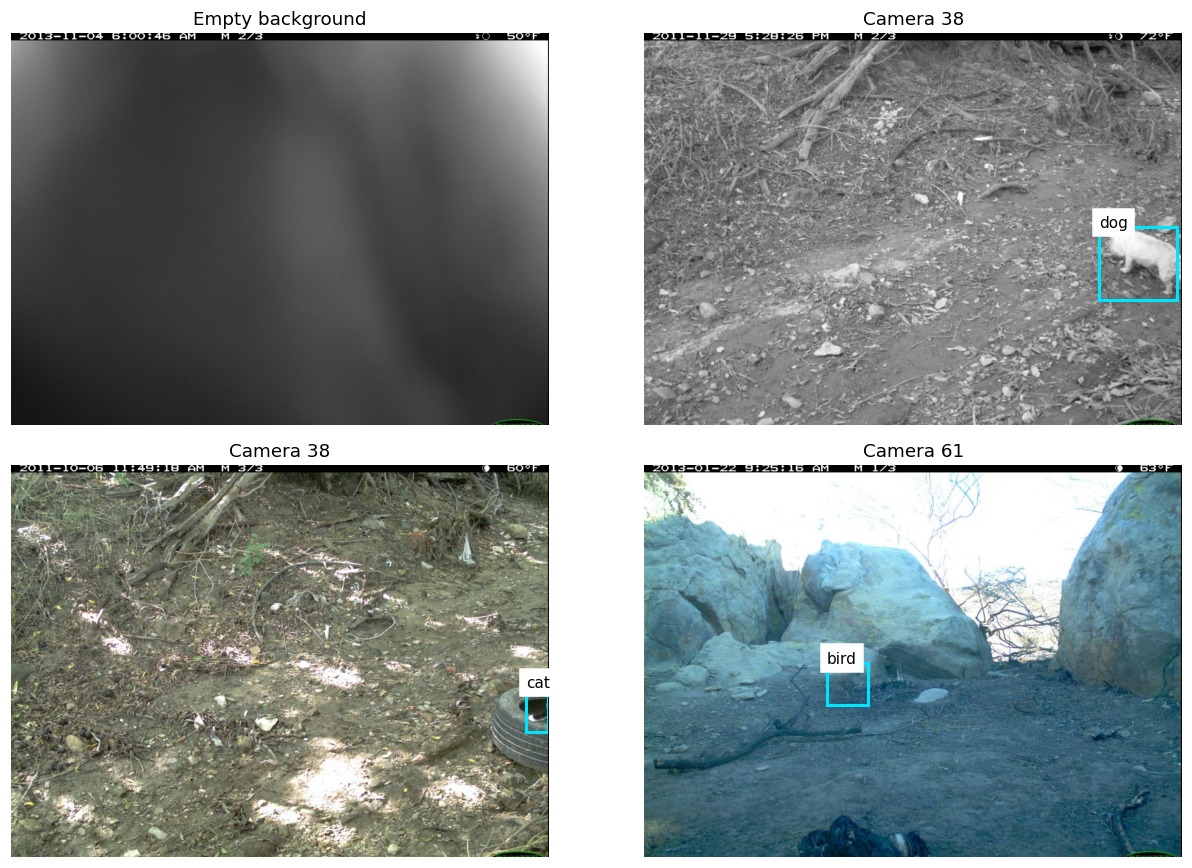

In [10]:
def materialize(records: dict, names: list[str]) -> dict:
    dataset = OUTPUT / "dataset"
    previous = OUTPUT / "jpeg_canonicalization.json"
    canonical = read_json(previous)["copies"] if previous.exists() else []
    for split, rows in records.items():
        for index, row in enumerate(rows, 1):
            source = Path(row["source"])
            stem = fingerprint(row["image_id"])[:24]
            target = dataset / "images" / split / f"{stem}{source.suffix.lower()}"
            target.parent.mkdir(parents=True, exist_ok=True)
            changed = canonical_jpeg(source, target, row["source_sha256"])
            if changed:
                canonical.append(changed)
            else:
                shutil.copyfile(source, target)  # Independent file: a loader cannot rewrite the source through a link.
                assert file_sha256(target) == row["source_sha256"]
            row["image"] = str(target)
            label = dataset / "labels" / split / f"{stem}.txt"
            label.parent.mkdir(parents=True, exist_ok=True)
            label.write_text("".join(f"{box['class_id']} " + " ".join(f"{v:.8f}" for v in box["box"]) + "\n"
                                     for box in row["boxes"]), encoding="utf-8")
            if index % 5000 == 0 or index == len(rows):
                print(f"Working copies {split}: {index}/{len(rows)}", flush=True)
    base = {"path": str(dataset), "train": "images/train", "val": "images/val", "names": names}
    (dataset / "data.yaml").write_text(yaml.safe_dump(base, sort_keys=False), encoding="utf-8")
    write_json(OUTPUT / "jpeg_canonicalization.json", {"copies": canonical,
        "originals_modified": False, "method": "remove only trailing whitespace after JPEG end marker; pixels verified identical"})
    return records

def verify_loader(records: dict, names: list[str]) -> list[dict]:
    from ultralytics.data.utils import verify_image_label
    result = []
    for split, rows in records.items():
        args = [(row["image"], str(OUTPUT / "dataset/labels" / split / (Path(row["image"]).stem + ".txt")),
                 "", False, len(names), 0, 0, False) for row in rows]
        with ThreadPoolExecutor(max_workers=4) as pool:
            checked = list(pool.map(verify_image_label, args))
        for row, entry in zip(rows, checked, strict=True):
            image, labels, _, _, _, missing, found, empty, corrupt, message = entry
            expected = np.asarray([[box["class_id"], *box["box"]] for box in row["boxes"]], dtype=np.float32)
            assert image is not None and not corrupt and not missing and found == 1 and not message, (row["image_id"], message)
            assert len(labels) == len(expected) and bool(empty) == (not row["boxes"])
            if len(expected):
                assert np.allclose(labels, expected, rtol=0, atol=5e-7)
        result.append({"split": split, "accepted_images": len(rows),
                       "backgrounds": sum(not row["boxes"] for row in rows)})
        print("Loader verified:", result[-1], flush=True)
    write_json(OUTPUT / "loader_verification.json", result)
    return result

records = copy.deepcopy(manifest["records"])
if SMOKE:
    records = {"train": _smoke_sample(records["train"], len(manifest["names"]), 2, 12, SEED),
               "val": _smoke_sample(records["val"], len(manifest["names"]), 1, 6, SEED + 1)}
records = materialize(records, manifest["names"])
loader_receipt = verify_loader(records, manifest["names"])
write_json(OUTPUT / "working_records.json", records)

def show_examples(rows: list[dict], names: list[str]) -> None:
    selected = [next(row for row in rows if not row["boxes"])]
    selected += [row for row in rows if row["boxes"]][:3]
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    for ax, row in zip(axes.flat, selected, strict=True):
        with Image.open(row["image"]) as image:
            ax.imshow(image)
            width, height = image.size
        for box in row["boxes"]:
            cx, cy, w, h = box["box"]
            ax.add_patch(patches.Rectangle(((cx-w/2)*width, (cy-h/2)*height), w*width, h*height,
                                           fill=False, edgecolor="#00E5FF", linewidth=2))
            ax.text((cx-w/2)*width, (cy-h/2)*height, names[box["class_id"]], color="black", backgroundcolor="white")
        ax.set_title("Empty background" if not row["boxes"] else f"Camera {row['camera_id']}")
        ax.axis("off")
    fig.tight_layout()
    fig.savefig(OUTPUT / "label_examples.png", bbox_inches="tight")
    plt.show()

show_examples(records["train"], manifest["names"])


Las siguientes funciones implementan la evaluación y sus comprobaciones antes de
iniciar el entrenamiento costoso. Se usa AP COCO: IoU 0,50:0,95, 101 puntos de recall,
máximo 300 detecciones por fotografía. La confianza de inferencia para AP es 0,001;
el umbral operativo del monitoreo será 0,25.

In [11]:
def coco_evaluate(
    records: list[dict],
    predictions: list[dict],
    names: list[str],
    area_range: tuple[float, float] | None = None,
    occlusions: dict | None = None,
    occlusion_group: str | None = None,
    return_evaluator: bool = False,
) -> dict:
    """Evaluate fixed categories at IoU 0.50:0.95 using 101 recall points.

    Coordinates use a virtual 1000x1000 image, preserving each image's IoU while
    allowing size strata based on relative box area. Other occlusion strata are
    represented as ignored crowd regions, so correct detections of them are not FPs.
    """
    ids = {record["image_id"]: index + 1 for index, record in enumerate(records)}
    if len(ids) != len(records) or not names or len(set(names)) != len(names):
        raise ValueError("Evaluation requires unique images and category names.")
    for prediction in predictions:
        coordinates = prediction["bbox"]
        if prediction["image_id"] not in ids or not 0 <= prediction["class_id"] < len(names):
            raise ValueError("Prediction refers to an unknown image or category.")
        if (
            len(coordinates) != 4
            or not np.isfinite([*coordinates, prediction["confidence"]]).all()
            or min(coordinates[2:]) < 0
            or not 0 <= prediction["confidence"] <= 1
        ):
            raise ValueError("Invalid prediction coordinates or confidence.")
        # Clipped zero-area predictions remain false-positive candidates in COCO.
    images, annotations = [], []
    annotation_id = 0
    eligible = 0
    for record in records:
        images.append({"id": ids[record["image_id"]], "width": 1000, "height": 1000})
        for box in record["boxes"]:
            if not 0 <= box["class_id"] < len(names):
                raise ValueError("Ground truth refers to an unknown category.")
            annotation_id += 1
            cx, cy, width, height = box["box"]
            crowd = int(occlusion_group is not None and (occlusions or {}).get(box["annotation_id"]) != occlusion_group)
            area = width * height * 1e6
            eligible += int(not crowd and (area_range is None or area_range[0] <= area <= area_range[1]))
            annotations.append(
                {
                    "id": annotation_id,
                    "image_id": ids[record["image_id"]],
                    "category_id": box["class_id"] + 1,
                    "bbox": [(cx - width / 2) * 1000, (cy - height / 2) * 1000, width * 1000, height * 1000],
                    "area": area,
                    "iscrowd": crowd,
                }
            )
    if not eligible:
        if return_evaluator:
            return None
        return {
            "map50": None,
            "map50_95": None,
            "eligible_objects": 0,
            "max_detections": 300,
            "per_species": [{"species": name, "support": 0, "map50": None, "map50_95": None} for name in names],
        }
    detections = []
    for prediction in predictions:
        x, y, width, height = prediction["bbox"]
        detections.append(
            {
                "image_id": ids[prediction["image_id"]],
                "category_id": prediction["class_id"] + 1,
                "bbox": [x * 1000, y * 1000, width * 1000, height * 1000],
                "score": prediction["confidence"],
            }
        )
    # pycocotools.loadRes requires at least one detection; empty predictions are valid zero AP.
    with contextlib.redirect_stdout(io.StringIO()):
        truth = COCO()
        truth.dataset = {
            "info": {},
            "images": images,
            "annotations": annotations,
            "categories": [{"id": i + 1, "name": name} for i, name in enumerate(names)],
        }
        truth.createIndex()
        if detections:
            detected = truth.loadRes(detections)
        else:
            detected = COCO()
            detected.dataset = {"images": images, "annotations": [], "categories": truth.dataset["categories"]}
            detected.createIndex()
        evaluator = COCOeval(truth, detected, "bbox")
        evaluator.params.imgIds = list(ids.values())
        evaluator.params.catIds = list(range(1, len(names) + 1))
        evaluator.params.maxDets = [1, 10, 300]
        if area_range:
            evaluator.params.areaRng = [list(area_range)]
            evaluator.params.areaRngLbl = ["selected"]
        evaluator.evaluate()
        evaluator.accumulate()
    if return_evaluator:
        return evaluator
    precision = evaluator.eval["precision"][:, :, :, 0, -1]

    def mean_defined(values):
        defined = values[values >= 0]
        return float(defined.mean()) if defined.size else None

    return {
        "map50": mean_defined(precision[0]),
        "map50_95": mean_defined(precision),
        "eligible_objects": eligible,
        "max_detections": 300,
        "per_species": [
            {
                "species": name,
                "support": sum(
                    annotation["category_id"] == index + 1
                    and not annotation["iscrowd"]
                    and (area_range is None or area_range[0] <= annotation["area"] <= area_range[1])
                    for annotation in annotations
                ),
                "map50": mean_defined(precision[0, :, index]),
                "map50_95": mean_defined(precision[:, :, index]),
            }
            for index, name in enumerate(names)
        ],
    }

def activity_report(frames: list[dict], detections: list[dict], names: list[str], confidence=0.25) -> dict:
    """Aggregate detections and empty-photo rates by camera and capture day."""
    ids = [frame["image_id"] for frame in frames]
    identifiers = set(ids)
    if len(ids) != len(identifiers):
        raise ValueError("Duplicate frames would inflate ecological activity counts.")
    by_image = defaultdict(list)
    for detection in detections:
        if detection["image_id"] not in identifiers:
            raise ValueError("Detection refers to a frame without camera metadata.")
        if not 0 <= detection["class_id"] < len(names) or not 0 <= detection["confidence"] <= 1:
            raise ValueError("Invalid detection class or confidence.")
        if detection["confidence"] >= confidence:
            by_image[detection["image_id"]].append(detection)
    groups = defaultdict(
        lambda: {
            "photos": 0,
            "positive_photos": 0,
            "species": set(),
            "counts": defaultdict(int),
            "species_photos": defaultdict(int),
        }
    )
    for frame in frames:
        try:
            date = datetime.fromisoformat((frame.get("timestamp") or "").replace("Z", "+00:00")).date().isoformat()
        except (ValueError, TypeError):
            date = "unknown"
        group = groups[(frame["camera_id"], date)]
        group["photos"] += 1
        predictions = by_image[frame["image_id"]]
        group["positive_photos"] += bool(predictions)
        present = set()
        for prediction in predictions:
            species = names[prediction["class_id"]]
            group["species"].add(species)
            group["counts"][species] += 1
            present.add(species)
        for species in present:
            group["species_photos"][species] += 1
    cameras, species_rows = [], []
    for (camera, date), group in sorted(groups.items()):
        cameras.append(
            {
                "camera_id": camera,
                "date": date,
                "photos": group["photos"],
                "photos_with_fauna": group["positive_photos"],
                "empty_photo_rate": 1 - group["positive_photos"] / group["photos"],
                "distinct_species": len(group["species"]),
            }
        )
        for species, count in sorted(group["counts"].items()):
            species_rows.append(
                {
                    "camera_id": camera,
                    "date": date,
                    "species": species,
                    "detections": count,
                    "photos_with_species": group["species_photos"][species],
                }
            )
    return {
        "camera_days": cameras,
        "species_days": species_rows,
        "confidence": confidence,
        "interpretation": "counts are detections and photographs, never unique individual animals",
    }


In [12]:
def ap_from_image_evaluations(evaluations: list, image_order: np.ndarray) -> tuple[float, float] | None:
    """Accumulate COCO AP from matched images, preserving resampled order and score ties."""
    chosen = [evaluations[int(index)] for index in image_order if evaluations[int(index)] is not None]
    if not chosen:
        return None
    positives = sum(np.count_nonzero(item["gtIgnore"] == 0) for item in chosen)
    if not positives:
        return None
    scores = np.concatenate([np.asarray(item["dtScores"])[:300] for item in chosen])
    if not len(scores):
        return 0.0, 0.0
    order = np.argsort(-scores, kind="mergesort")
    matches = np.concatenate([item["dtMatches"][:, :300] for item in chosen], axis=1)[:, order] > 0
    ignored = np.concatenate([item["dtIgnore"][:, :300] for item in chosen], axis=1)[:, order]
    tp = np.cumsum(matches & ~ignored, axis=1, dtype=float)
    fp = np.cumsum(~matches & ~ignored, axis=1, dtype=float)
    recalls = tp / positives
    precision = tp / (tp + fp + np.spacing(1))
    precision = np.maximum.accumulate(precision[:, ::-1], axis=1)[:, ::-1]
    sampled_precision = np.zeros((10, 101), dtype=float)
    for iou in range(10):
        indices = np.searchsorted(recalls[iou], np.linspace(0, 1, 101), side="left")
        valid = indices < precision.shape[1]
        sampled_precision[iou, valid] = precision[iou, indices[valid]]
    return float(sampled_precision[0].mean()), float(sampled_precision.mean())

def sequence_bootstrap(records: list[dict], predictions: list[dict], names: list[str],
                       replicates: int = 200, seed: int = 42, **kwargs) -> dict:
    """Reuse COCO per-image matching; resample whole sequences and recompute accumulation."""
    evaluator = coco_evaluate(records, predictions, names, return_evaluator=True, **kwargs)
    if evaluator is None:
        return {"replicates": replicates, "intervals": {key: {"lower": None, "upper": None,
                "defined_replicates": 0} for key in ("map50", "map50_95")}}
    clusters = defaultdict(list)
    for index, row in enumerate(records):
        assert row.get("sequence_id")
        clusters[row["sequence_id"]].append(index)
    sequences = sorted(clusters)
    assert len(sequences) >= 2 and replicates >= 2
    rng = np.random.default_rng(seed)
    stride = len(evaluator.params.areaRng) * len(records)
    by_category = [evaluator.evalImgs[i * stride:i * stride + len(records)] for i in range(len(names))]
    values = {"map50": [], "map50_95": []}
    for replicate in range(replicates):
        image_order = np.asarray([index for choice in rng.integers(0, len(sequences), len(sequences))
                                  for index in clusters[sequences[choice]]], dtype=int)
        category_values = [value for category in by_category
                           if (value := ap_from_image_evaluations(category, image_order)) is not None]
        if category_values:
            means = np.mean(category_values, axis=0)
            values["map50"].append(float(means[0]))
            values["map50_95"].append(float(means[1]))
        if (replicate + 1) % 20 == 0 or replicate + 1 == replicates:
            print(f"Sequence bootstrap: {replicate + 1}/{replicates}; {kwargs}", flush=True)
    return {"method": "percentile sequence-cluster bootstrap; COCO image matching reused; fixed checkpoint",
            "replicates": replicates, "seed": seed, "clusters": len(sequences), "confidence_level": 0.95,
            "intervals": {key: {"lower": float(np.quantile(value, 0.025)) if value else None,
                                "upper": float(np.quantile(value, 0.975)) if value else None,
                                "defined_replicates": len(value)} for key, value in values.items()}}

def run_unit_checks() -> list[str]:
    passed = []
    assert normalize_box([20, 10, 40, 20], 200, 100, "pixels") == [0.2, 0.2, 0.2, 0.2]
    for bad in ([-1, 0, 2, 2], [0, 0, 0, 2], [199, 0, 3, 2], [0, 0, float("nan"), 2]):
        try:
            normalize_box(bad, 200, 100, "pixels")
        except ValueError:
            continue
        raise AssertionError("Invalid box was accepted")
    passed.append("bbox_normalization_and_invalid_coordinates")
    rows = [{"image_id": "a", "sequence_id": "s1", "camera_id": "c", "timestamp": "2020-01-01 01:00:00",
             "boxes": [{"class_id": 0, "box": [0.5, 0.5, 0.2, 0.2], "annotation_id": "a1"}]},
            {"image_id": "b", "sequence_id": "s2", "camera_id": "c", "timestamp": "2020-01-01 02:00:00",
             "boxes": [{"class_id": 0, "box": [0.5, 0.5, 0.2, 0.2], "annotation_id": "b1"}]},
            {"image_id": "e", "sequence_id": "s3", "camera_id": "c", "timestamp": "2020-01-01 03:00:00", "boxes": []}]
    detected = [{"image_id": "a", "class_id": 0, "confidence": 0.9, "bbox": [0.4, 0.4, 0.2, 0.2]},
                {"image_id": "b", "class_id": 0, "confidence": 0.8, "bbox": [0.4, 0.4, 0.2, 0.2]}]
    perfect = coco_evaluate(rows, detected, ["animal", "unsupported"])
    assert np.isclose(perfect["map50_95"], 1)
    assert perfect["per_species"][1]["map50"] is None
    assert coco_evaluate(rows, [], ["animal"])["map50_95"] == 0
    passed += ["perfect_detection", "missing_class_is_undefined", "empty_predictions_are_zero_ap"]
    false_positive = {"image_id": "e", "class_id": 0, "confidence": 0.99, "bbox": [0.4, 0.4, 0.2, 0.2]}
    assert coco_evaluate(rows, detected + [false_positive], ["animal"])["map50"] < perfect["map50"]
    passed.append("false_positives_on_empty_frames_count")
    ignored = coco_evaluate(rows, detected, ["animal"], occlusions={"a1": "low", "b1": "high"}, occlusion_group="low")
    assert ignored["eligible_objects"] == 1 and np.isclose(ignored["map50_95"], 1)
    passed.append("other_occlusion_levels_are_ignored")
    report = activity_report(rows, detected + [{**detected[0], "confidence": 0.7}], ["animal"])
    assert report["camera_days"][0]["photos_with_fauna"] == 2
    assert report["species_days"][0]["detections"] == 3 and report["species_days"][0]["photos_with_species"] == 2
    assert np.isclose(report["camera_days"][0]["empty_photo_rate"], 1/3)
    try:
        activity_report(rows + [rows[0]], detected, ["animal"])
    except ValueError:
        pass
    else:
        raise AssertionError("Duplicate photographs accepted")
    passed += ["activity_counts_photos_once_per_species", "activity_rejects_duplicate_photos"]
    # Compare the optimized resampling against independent, complete COCO reevaluation.
    test_predictions = [detected[0], false_positive]
    fast = sequence_bootstrap(rows, test_predictions, ["animal"], replicates=6, seed=7)
    rng = np.random.default_rng(7)
    slow_values = []
    for _ in range(6):
        selected, predictions = [], []
        for index in rng.integers(0, 3, 3):
            before = rows[index]
            identifier = f"sample-{len(selected)}"
            selected.append({**before, "image_id": identifier})
            predictions.extend({**prediction, "image_id": identifier} for prediction in test_predictions
                               if prediction["image_id"] == before["image_id"])
        score = coco_evaluate(selected, predictions, ["animal"])
        if score["map50_95"] is not None:
            slow_values.append(score["map50_95"])
    assert np.allclose([fast["intervals"]["map50_95"]["lower"], fast["intervals"]["map50_95"]["upper"]],
                       np.quantile(slow_values, [0.025, 0.975]), rtol=0, atol=1e-12)
    passed.append("optimized_sequence_bootstrap_matches_complete_coco")
    return passed

UNIT_CHECKS = run_unit_checks()
write_json(OUTPUT / "unit_checks.json", {"passed": UNIT_CHECKS})
display(pd.DataFrame({"check": UNIT_CHECKS, "status": "passed"}))


Sequence bootstrap: 6/6; {}


,check,status
0,bbox_normalization_and_invalid_coordinates,passed
1,perfect_detection,passed
2,missing_class_is_undefined,passed
3,empty_predictions_are_zero_ap,passed
4,false_positives_on_empty_frames_count,passed
5,other_occlusion_levels_are_ignored,passed
6,activity_counts_photos_once_per_species,passed
7,activity_rejects_duplicate_photos,passed
8,optimized_sequence_bootstrap_matches_complete_...,passed


Se usa un detector YOLO existente y se implementan aquí preparación, auditoría,
evaluación, explicabilidad y monitoreo. Se conserva la decisión del proyecto de ajustar
YOLOv8s; esto no equivale a una confirmación del docente sobre la regla general de
implementar componentes arquitectónicos.

**Protocolo:** semilla 42, entrada 640, AdamW, tasa inicial 0,0003, weight decay 0,0001,
50 épocas como máximo, paciencia 10, mosaic 1,0 y cierre en las últimas 10 épocas,
reflexión horizontal 0,5 y vertical 0. El lote GPU de referencia es 16; en CPU es 2.
Se registra el lote efectivo si Ultralytics debe ajustarlo por memoria. Las curvas y
la mejor época proceden de esta ejecución, sin fijar de antemano sus resultados.

Temporary training cache: 2.03 GiB; permanent artifacts stay at E:\Kaggle\exam-output-wildlife-notebook\full-20261025T222726_615921Z


Epoch 1: val mAP50=0.4092; mAP50:95=0.2374


Epoch 2: val mAP50=0.6819; mAP50:95=0.4324


Epoch 3: val mAP50=0.7223; mAP50:95=0.4539


Epoch 4: val mAP50=0.7453; mAP50:95=0.4781


...

Epoch 46: val mAP50=0.9157; mAP50:95=0.5833


Epoch 47: val mAP50=0.9193; mAP50:95=0.5856


Epoch 48: val mAP50=0.9215; mAP50:95=0.5853


Epoch 48: val mAP50=0.9167; mAP50:95=0.5913


,epoch,train/box_loss,train/cls_loss,metrics/mAP50(B),metrics/mAP50-95(B)
0,1,1.56293,2.16141,0.40918,0.23744
1,2,1.47274,1.44822,0.68191,0.43236
2,3,1.43855,1.26880,0.72231,0.45389
3,4,1.39612,1.15873,0.74526,0.47808
4,5,1.37733,1.07009,0.79090,0.51203
5,6,1.35911,1.01556,0.76899,0.50413
6,7,1.33767,0.97393,0.79076,0.51312
7,8,1.32531,0.91944,0.77381,0.50722
8,9,1.30656,0.88326,0.79617,0.53278
9,10,1.31043,0.86580,0.80363,0.53566


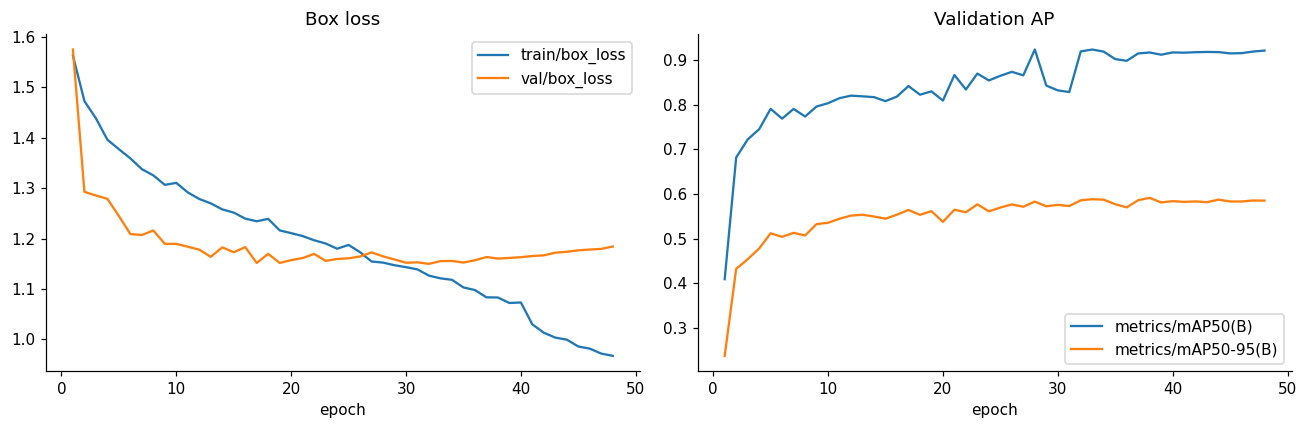

New trained checkpoint: 30c66beafdae0619acf91c4f9a4c50c8c4ecd244724c24328c0f254369b6031e


In [13]:
from ultralytics.utils import LOGGER

training_config = {"data": str(OUTPUT / "dataset/data.yaml"), "epochs": 1 if SMOKE else 50,
    "patience": 10, "imgsz": 640, "batch": BATCH, "workers": 0, "device": DEVICE,
    "amp": DEVICE == 0, "seed": SEED, "deterministic": True, "optimizer": "AdamW",
    "lr0": 0.0003, "weight_decay": 0.0001, "cache": False, "mosaic": 1.0,
    "fliplr": 0.5, "flipud": 0.0, "close_mosaic": 0 if SMOKE else 10,
    "fraction": 1.0, "project": str(OUTPUT), "name": "yolov8s", "exist_ok": False,
    "plots": True, "verbose": False}
weights_receipt = obtain_original(MODEL_BASE + "yolov8s.pt", PRETRAINED, PRETRAINED_EXPECTED_SHA256)
initial_weights = OUTPUT / "weights-cache/yolov8s.pt"
initial_weights.parent.mkdir(parents=True, exist_ok=True)
shutil.copyfile(PRETRAINED, initial_weights)
PRETRAINED_SHA256 = file_sha256(initial_weights)
assert PRETRAINED_SHA256 == weights_receipt["sha256"]
# This general detector is used only by the installed library's AMP self-check.
if DEVICE == 0:
    amp_source = PRETRAINED.with_name("yolo26n.pt")
    obtain_original(MODEL_BASE + "yolo26n.pt", amp_source, AMP_PRETRAINED_EXPECTED_SHA256)
    shutil.copyfile(amp_source, initial_weights.with_name("yolo26n.pt"))
write_json(OUTPUT / "pretrained_source.json", weights_receipt)
TRAINING_CACHE = None
training_bytes = sum(Path(row["image"]).stat().st_size for split in ("train", "val") for row in records[split])
if not SMOKE and shutil.disk_usage(tempfile.gettempdir()).free > training_bytes * 1.5 + 1024**3:
    TRAINING_CACHE = tempfile.TemporaryDirectory(prefix="fauna-training-")
    local_dataset = Path(TRAINING_CACHE.name)
    for split in ("train", "val"):
        (local_dataset / "images" / split).mkdir(parents=True)
        (local_dataset / "labels" / split).mkdir(parents=True)
        for row in records[split]:
            image = Path(row["image"])
            shutil.copyfile(image, local_dataset / "images" / split / image.name)
            label = OUTPUT / "dataset/labels" / split / (image.stem + ".txt")
            shutil.copyfile(label, local_dataset / "labels" / split / label.name)
    (local_dataset / "data.yaml").write_text(yaml.safe_dump({"path": str(local_dataset),
        "train": "images/train", "val": "images/val", "names": manifest["names"]}), encoding="utf-8")
    training_config["data"] = str(local_dataset / "data.yaml")
    print(f"Temporary training cache: {training_bytes / 1024**3:.2f} GiB; permanent artifacts stay at {OUTPUT}", flush=True)
write_json(OUTPUT / "training_protocol.json", {"config": training_config, "versions": VERSIONS,
    "manifest_identity": manifest["identity"], "pretrained_sha256": PRETRAINED_SHA256,
    "checkpoint_selection": "maximum validation mAP50:95 on cis_val only", "scientific_run": not SMOKE})

model = YOLO(str(initial_weights))
epoch_rows = []
notebook_stdout = sys.stdout

def report_epoch(trainer) -> None:
    row = {"epoch": trainer.epoch + 1, **{key: float(value) for key, value in trainer.metrics.items()}}
    epoch_rows.append(row)
    write_json(OUTPUT / "epoch_progress.json", epoch_rows)
    print(f"Epoch {row['epoch']}: val mAP50={row.get('metrics/mAP50(B)', float('nan')):.4f}; "
          f"mAP50:95={row.get('metrics/mAP50-95(B)', float('nan')):.4f}", file=notebook_stdout, flush=True)

model.add_callback("on_fit_epoch_end", report_epoch)
training_started = time.time()
with (OUTPUT / "training.log").open("w", encoding="utf-8") as training_log:
    handlers = [(handler, handler.stream) for handler in LOGGER.handlers if hasattr(handler, "stream")]
    for handler, _ in handlers:
        handler.setStream(training_log)
    try:
        with contextlib.redirect_stdout(training_log), contextlib.redirect_stderr(training_log):
            model.train(**training_config)
    finally:
        for handler, stream in handlers:
            handler.setStream(stream)

BEST = OUTPUT / "yolov8s/weights/best.pt"
assert BEST.is_file()
CHECKPOINT_SHA256 = file_sha256(BEST)
assert CHECKPOINT_SHA256 != PRETRAINED_SHA256
training = pd.read_csv(OUTPUT / "yolov8s/results.csv")
training.columns = training.columns.str.strip()
assert 1 <= len(training) <= training_config["epochs"]
TRAINING_RECEIPT = {"checkpoint": str(BEST), "checkpoint_sha256": CHECKPOINT_SHA256,
    "pretrained_sha256": PRETRAINED_SHA256, "epochs": len(training), "seconds": time.time() - training_started,
    "selected_epoch": int(training.loc[training["metrics/mAP50-95(B)"].idxmax(), "epoch"]),
    "effective_batch": int(model.trainer.batch_size),
    "scientific_run": not SMOKE, "selection": "validation only", "reused_fauna_checkpoint": False}
write_json(OUTPUT / "training_complete.json", TRAINING_RECEIPT)
display(training[["epoch", "train/box_loss", "train/cls_loss", "metrics/mAP50(B)", "metrics/mAP50-95(B)"]])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
training.plot(x="epoch", y=["train/box_loss", "val/box_loss"], ax=axes[0], title="Box loss")
training.plot(x="epoch", y=["metrics/mAP50(B)", "metrics/mAP50-95(B)"], ax=axes[1], title="Validation AP")
fig.tight_layout()
fig.savefig(OUTPUT / "training_curves.png", bbox_inches="tight")
plt.show()
print("New trained checkpoint:", CHECKPOINT_SHA256)


## 2. Evaluación cuantitativa y desbalance entre especies

Se vuelve a cargar el checkpoint seleccionado y se generan predicciones nuevas en ambos
tests. Las imágenes vacías permanecen presentes para contabilizar falsos positivos.
La ausencia de ejemplos de una especie deja su AP indefinida, no igual a cero.

cis_test: 8/13073


cis_test: 808/13073


cis_test: 1608/13073


cis_test: 2408/13073


cis_test: 3208/13073


...

trans_test: 17608/18647


trans_test: 18408/18647


trans_test: 18647/18647


,split,mAP@0.5,mAP@0.5:0.95
0,cis_test,0.693648,0.441168
1,trans_test,0.445029,0.275864


,split,training_boxes,species,support,map50,map50_95
0,cis_test,2514,opossum,4008,0.869224,0.487392
1,cis_test,1024,raccoon,980,0.908233,0.607288
2,cis_test,1036,squirrel,510,0.720399,0.386100
3,cis_test,682,bobcat,772,0.807080,0.572402
4,cis_test,214,skunk,161,0.951298,0.617808
5,cis_test,764,dog,723,0.730196,0.520832
6,cis_test,1368,coyote,1180,0.914033,0.693810
7,cis_test,2266,rabbit,1556,0.889533,0.558541
8,cis_test,556,bird,752,0.663091,0.353678
9,cis_test,1168,cat,1528,0.870264,0.588521


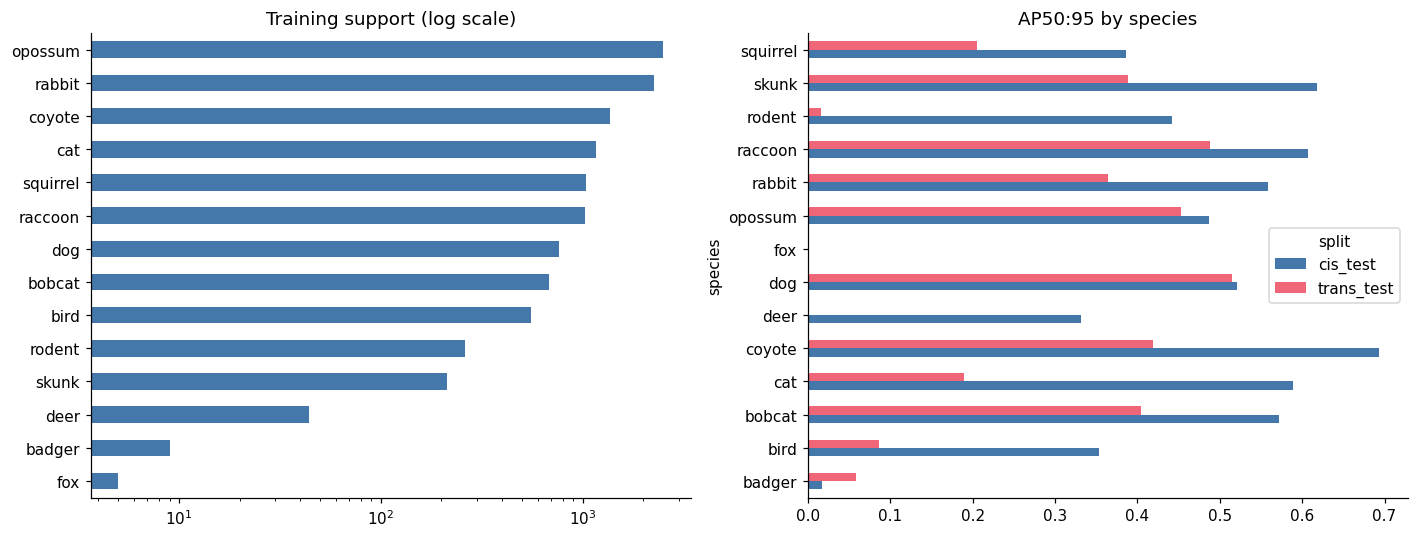

Las especies con muy pocas cajas de entrenamiento tienen estimaciones más inestables. El soporte se muestra junto a cada AP; la macro-mAP no está ponderada por frecuencia. El desbalance y la composición de los tests deben considerarse al comparar resultados.

In [14]:
def predict_records(model, rows: list[dict], label: str) -> list[dict]:
    detected = []
    signature = fingerprint({"checkpoint": CHECKPOINT_SHA256,
        "data": [(row["image_id"], row["source_sha256"]) for row in rows],
        "imgsz": 640, "conf": 0.001, "iou": 0.7, "max_det": 300})
    for start in range(0, len(rows), PREDICTION_BATCH):
        chunk = rows[start:start + PREDICTION_BATCH]
        results = model.predict([row["image"] for row in chunk], imgsz=640, conf=0.001, iou=0.7,
                                max_det=300, stream=True, batch=PREDICTION_BATCH, device=DEVICE, verbose=False)
        batch_predictions = []
        for row, result in zip(chunk, results, strict=True):
            boxes = result.boxes
            for xyxy, confidence, category in zip(boxes.xyxyn.cpu().tolist(), boxes.conf.cpu().tolist(),
                                                  boxes.cls.cpu().tolist(), strict=True):
                x1, y1, x2, y2 = xyxy
                batch_predictions.append({"image_id": row["image_id"], "class_id": int(category),
                                          "confidence": confidence, "bbox": [x1, y1, x2-x1, y2-y1]})
        detected.extend(batch_predictions)
        if start % (PREDICTION_BATCH * 100) == 0 or start + PREDICTION_BATCH >= len(rows):
            print(f"{label}: {min(start+PREDICTION_BATCH, len(rows))}/{len(rows)}", flush=True)
    write_json(OUTPUT / label / "predictions.json", {"signature": signature, "checkpoint_sha256": CHECKPOINT_SHA256,
        "image_ids": [row["image_id"] for row in rows], "predictions": detected})
    return detected

predictions, scores = {}, {}
if not SMOKE:
    model = YOLO(str(BEST))
    names = manifest["names"]
    for split in ("cis_test", "trans_test"):
        predictions[split] = predict_records(model, records[split], split)
        scores[split] = coco_evaluate(records[split], predictions[split], names)
        scores[split]["checkpoint_sha256"] = CHECKPOINT_SHA256
        write_json(OUTPUT / split / "metrics.json", scores[split])
    score_table = pd.DataFrame([{"split": split, "mAP@0.5": value["map50"], "mAP@0.5:0.95": value["map50_95"]}
                               for split, value in scores.items()])
    display(score_table)
    species_table = pd.DataFrame([{"split": split, "training_boxes": manifest["train_class_boxes"][row["species"]], **row}
                                  for split, value in scores.items() for row in value["per_species"]])
    write_csv(OUTPUT / "per_species_metrics.csv", species_table.to_dict("records"))
    display(species_table)
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    balance = pd.Series(manifest["train_class_boxes"]).sort_values()
    balance.plot.barh(ax=axes[0], logx=True, color="#4477AA", title="Training support (log scale)")
    species_table.pivot(index="species", columns="split", values="map50_95").plot.barh(
        ax=axes[1], color=["#4477AA", "#EE6677"], title="AP50:95 by species")
    fig.tight_layout()
    fig.savefig(OUTPUT / "species_balance_and_ap.png", bbox_inches="tight")
    plt.show()
    display(Markdown("Las especies con muy pocas cajas de entrenamiento tienen estimaciones más inestables. "
        "El soporte se muestra junto a cada AP; la macro-mAP no está ponderada por frecuencia. "
        "El desbalance y la composición de los tests deben considerarse al comparar resultados."))
else:
    print("Smoke: held-out scientific tests are not used.")


## 3. Generalización entre ubicaciones de cámara

Se contrastan `cis_test` —ubicaciones conocidas— y `trans_test` —ubicaciones nuevas—.
La brecha global también puede reflejar cambios de composición de especies; por eso se
incluye una segunda comparación sobre categorías con soporte en ambos tests.
Los mapas Grad-CAM explican una propuesta y clase antes de NMS. Muestran sensibilidad
local de la red; no prueban por sí solos que haya memorizado el fondo.
La explicación usa la capa 9 del backbone y una entrada de 640 × 640 con relleno proporcional (letterbox). Para una imagen anotada se toma, entre las 32 propuestas más próximas al centro de la caja, la de mayor puntuación de la clase; para un fondo se toma la máxima. Esa propuesta puede diferir de la detección final: su `score` no es la confianza posterior a NMS. Los rótulos de acierto, fallo o falso positivo sí se determinan con las predicciones finales al umbral 0,25.

El relleno artificial y las bandas de fecha también forman parte de la entrada y pueden activar el mapa. Activaciones fuera del animal no distinguen por sí solas entre contexto natural, relleno y texto. Un mapa uniforme o nulo resulta poco informativo; no demuestra que la red ignore al animal. Estos casos sirven para formular hipótesis que requieren pruebas controladas adicionales.


In [15]:
class GradCAM:
    """Capture feature gradients while avoiding full backward-hook/in-place conflicts."""

    def __init__(self, layer: nn.Module):
        self.features = None
        self.gradients = None
        self.handle = layer.register_forward_hook(self._capture)

    def _capture(self, module, inputs, output):
        self.features = output
        self.gradients = None
        output.register_hook(self._save_gradients)

    def _save_gradients(self, gradient):
        self.gradients = gradient

    def maps(self, score: torch.Tensor, size: tuple[int, int]) -> torch.Tensor:
        """Backpropagate a scalar score and normalize each captured image map."""
        score.backward()
        if self.gradients is None:
            raise RuntimeError("The selected score does not depend on the captured layer.")
        weights = self.gradients.mean(dim=(-2, -1), keepdim=True)
        maps = (weights * self.features).sum(dim=1, keepdim=True).relu()
        maps = F.interpolate(maps, size=size, mode="bilinear", align_corners=False).squeeze(1)
        minimum = maps.flatten(1).amin(1)[:, None, None]
        maximum = maps.flatten(1).amax(1)[:, None, None]
        return ((maps - minimum) / (maximum - minimum).clamp_min(1e-8)).detach()

    def close(self):
        """Remove hooks after the explanation to release feature references."""
        self.handle.remove()
        self.features = self.gradients = None

def _capture_period(record: dict) -> str:
    try:
        hour = datetime.fromisoformat(record.get("timestamp") or "").hour
    except (ValueError, TypeError):
        return "unknown"
    return "day" if 8 <= hour < 17 else "night" if hour >= 20 or hour < 5 else "transition"

def _box_iou(box: list, prediction: list) -> float:
    cx, cy, width, height = box
    x, y, predicted_width, predicted_height = prediction
    intersection = max(0, min(cx + width / 2, x + predicted_width) - max(cx - width / 2, x)) * max(
        0, min(cy + height / 2, y + predicted_height) - max(cy - height / 2, y)
    )
    return intersection / (width * height + predicted_width * predicted_height - intersection)

def _select_cam_records(manifest, predictions, split, confidence) -> list[tuple]:
    by_image = {}
    for prediction in predictions:
        if prediction["confidence"] >= confidence:
            by_image.setdefault(prediction["image_id"], []).append(prediction)
    pools = {"false_positive": [], "missed_or_wrong_class": [], "detected_iou50": []}
    ordered = sorted(manifest["records"][split], key=lambda row: row["image_id"])
    support = manifest["train_class_boxes"]
    for row in ordered:
        found = by_image.get(row["image_id"], [])
        if not row["boxes"] and found:
            pools["false_positive"].append(
                (row, max(found, key=lambda prediction: prediction["confidence"])["class_id"])
            )
        for box in row["boxes"]:
            detected = any(
                prediction["class_id"] == box["class_id"] and _box_iou(box["box"], prediction["bbox"]) >= 0.5
                for prediction in found
            )
            pools["detected_iou50" if detected else "missed_or_wrong_class"].append((row, box["class_id"]))
    selected, used = [], set()
    for kind, pool in pools.items():
        for index, period in enumerate(("day", "night")):
            available = [item for item in pool if item[0]["image_id"] not in used]
            if available:
                row, class_id = min(
                    available,
                    key=lambda item: (
                        _capture_period(item[0]) != period,
                        support[manifest["names"][item[1]]] * (1 if index == 0 else -1),
                        item[0]["image_id"],
                        item[1],
                    ),
                )
                selected.append((row, kind, class_id))
                used.add(row["image_id"])
    for row in ordered:
        if len(selected) >= 6:
            break
        if row["boxes"] and row["image_id"] not in used:
            selected.append((row, "representative", row["boxes"][0]["class_id"]))
            used.add(row["image_id"])
    return selected[:6]


In [16]:
def cam_plot(rgb: np.ndarray, heatmap: np.ndarray, destination: Path, title: str) -> None:
    fig, axes = plt.subplots(1, 2, figsize=(8, 4))
    axes[0].imshow(rgb)
    axes[0].set_title("Input (letterboxed)")
    axes[1].imshow(rgb)
    axes[1].imshow(heatmap, cmap="magma", alpha=0.5, vmin=0, vmax=1)
    axes[1].set_title(title)
    for ax in axes:
        ax.axis("off")
    fig.tight_layout()
    destination.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(destination, bbox_inches="tight")
    plt.close(fig)


def detection_cam(model, record, settings, output, names, target_class=None) -> dict:
    """Explain a fixed class/proposal before NMS and retain the letterbox geometry."""
    from ultralytics.data.augment import LetterBox

    class_id = record["boxes"][0]["class_id"] if target_class is None else target_class
    detector = model.model.to(torch.device("cuda:0" if DEVICE == 0 else "cpu")).float().eval()
    flags = [parameter.requires_grad for parameter in detector.parameters()]
    for parameter in detector.parameters():
        parameter.requires_grad_(True)
    with Image.open(record["image"]) as image:
        rgb = np.asarray(image.convert("RGB"))
    letterboxed = LetterBox(new_shape=(640,) * 2, auto=False)(image=rgb)
    tensor = (
        torch.from_numpy(letterboxed.copy()).permute(2, 0, 1).float()[None].to(next(detector.parameters()).device) / 255
    )
    detector.zero_grad(set_to_none=True)
    head = detector.model[-1]
    original_dynamic = head.dynamic
    head.dynamic = True
    capture = GradCAM(detector.model[9])
    try:
        raw = detector(tensor)
        decoded = raw[0] if isinstance(raw, tuple) else raw
        if decoded.ndim != 3 or decoded.shape[1] != 4 + len(names):
            raise ValueError("Expected a differentiable YOLOv8 [batch,4+classes,proposals] output.")
        scores = decoded[0, 4 + class_id]
        # Select the proposal closest to the target object; empty-photo cases use the maximum score.
        if record["boxes"]:
            box = next((box for box in record["boxes"] if box["class_id"] == class_id), record["boxes"][0])
            ratio = min(letterboxed.shape[1] / rgb.shape[1], letterboxed.shape[0] / rgb.shape[0])
            center = torch.tensor(
                [
                    box["box"][0] * rgb.shape[1] * ratio + (letterboxed.shape[1] - rgb.shape[1] * ratio) / 2,
                    box["box"][1] * rgb.shape[0] * ratio + (letterboxed.shape[0] - rgb.shape[0] * ratio) / 2,
                ],
                device=tensor.device,
            )
            distances = ((decoded[0, :2].T - center) ** 2).sum(1)
            closest = distances.topk(min(32, len(distances)), largest=False).indices
            proposal = closest[scores[closest].argmax()]
        else:
            proposal = scores.argmax()
        scalar = scores[proposal]
        heatmap = capture.maps(scalar, tensor.shape[-2:])[0].cpu().numpy()
        if not np.isfinite(heatmap).all():
            raise RuntimeError("Non-finite Grad-CAM output.")
        cam_plot(letterboxed, heatmap, output, f"Grad-CAM: {names[class_id]}")
        return {
            "class": names[class_id],
            "proposal": int(proposal),
            "score": float(scalar.detach()),
            "heatmap_range": [float(heatmap.min()), float(heatmap.max())],
        }
    finally:
        capture.close()
        head.dynamic = original_dynamic
        for parameter, flag in zip(detector.parameters(), flags, strict=True):
            parameter.requires_grad_(flag)


,first,second,shared_images,shared_sequences
0,train,val,0,0
1,train,cis_test,0,0
2,train,trans_val,0,0
3,train,trans_test,0,0
4,val,cis_test,0,0
5,val,trans_val,0,0
6,val,trans_test,0,0
7,cis_test,trans_val,0,0
8,cis_test,trans_test,0,0
9,trans_val,trans_test,0,0


,split,cameras
0,train,"106, 108, 115, 120, 23, 26, 33, 38, 43, 51, 57..."
1,val,"108, 115, 120, 33, 38, 43, 51, 61, 88, 90"
2,cis_test,"108, 115, 120, 33, 38, 43, 51, 61, 88, 90"
3,trans_val,125
4,trans_test,"0, 100, 105, 130, 28, 40, 46, 7, 78"


,comparison,map50,map50_95
0,all supported species,0.248618,0.165304
1,species supported in both tests,0.261576,0.173768


Sequence bootstrap: 20/200; {}


Sequence bootstrap: 40/200; {}


...

Sequence bootstrap: 140/200; {}


Sequence bootstrap: 160/200; {}


Sequence bootstrap: 180/200; {}


Sequence bootstrap: 200/200; {}


,split,lower,upper,defined_replicates
0,cis_test,0.433426,0.486176,200
1,trans_test,0.268503,0.315049,200


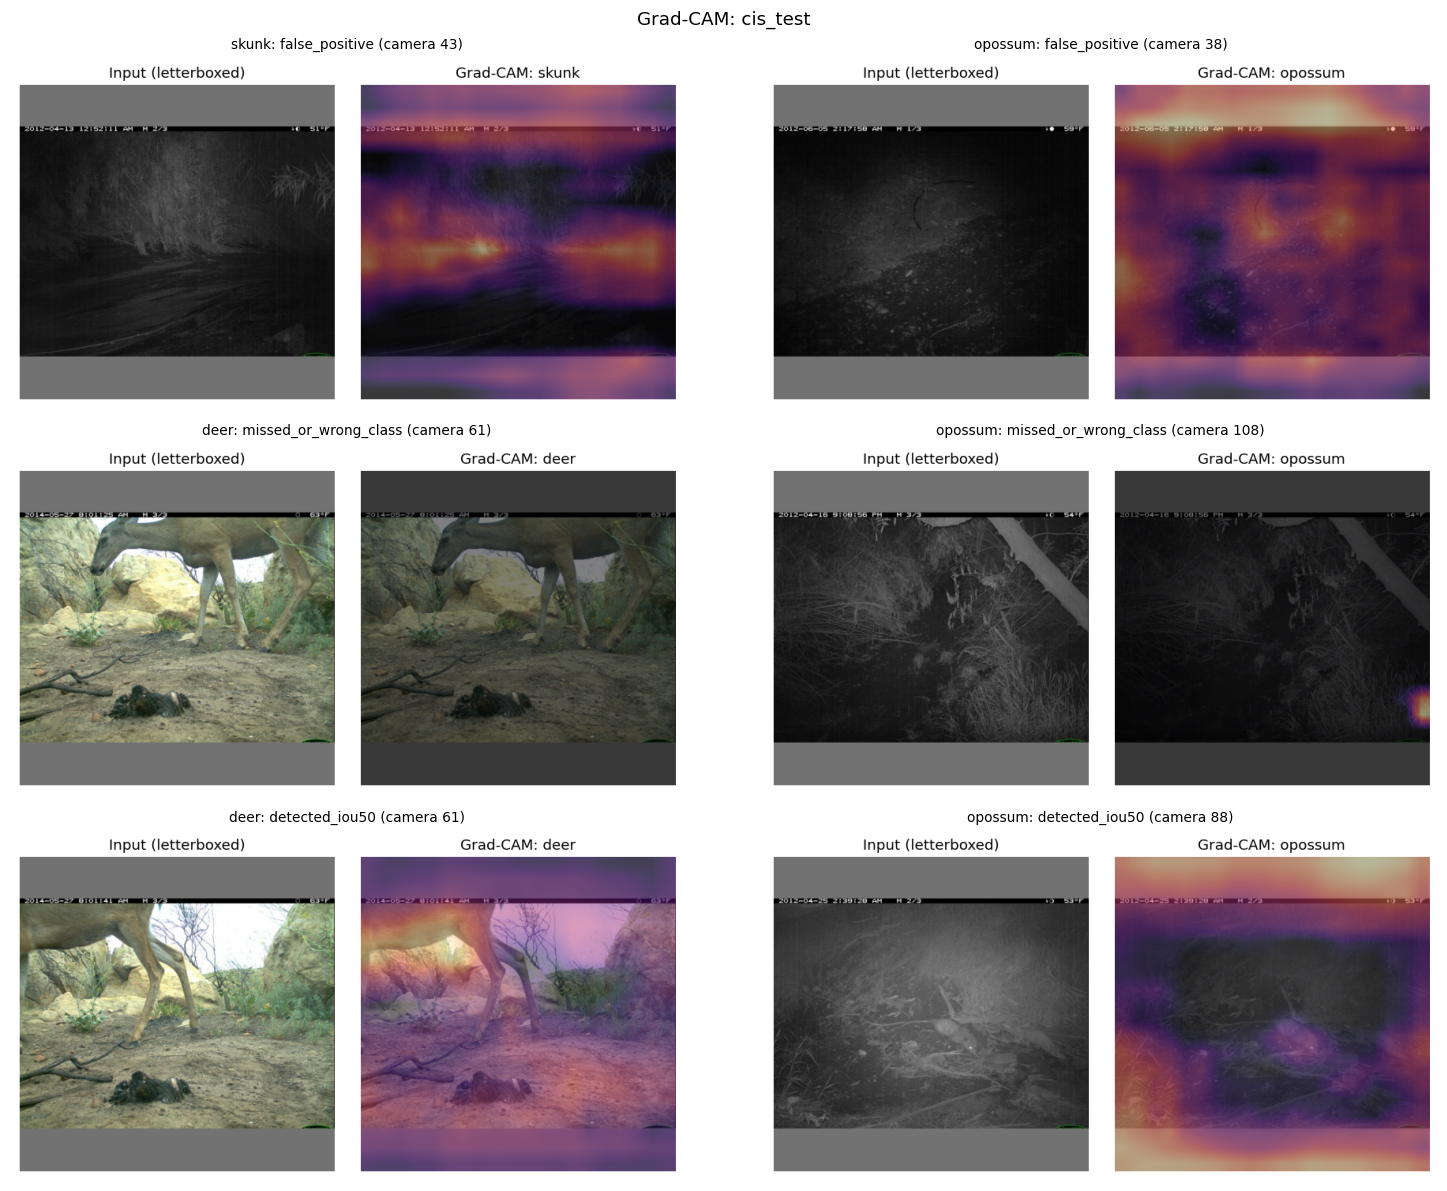

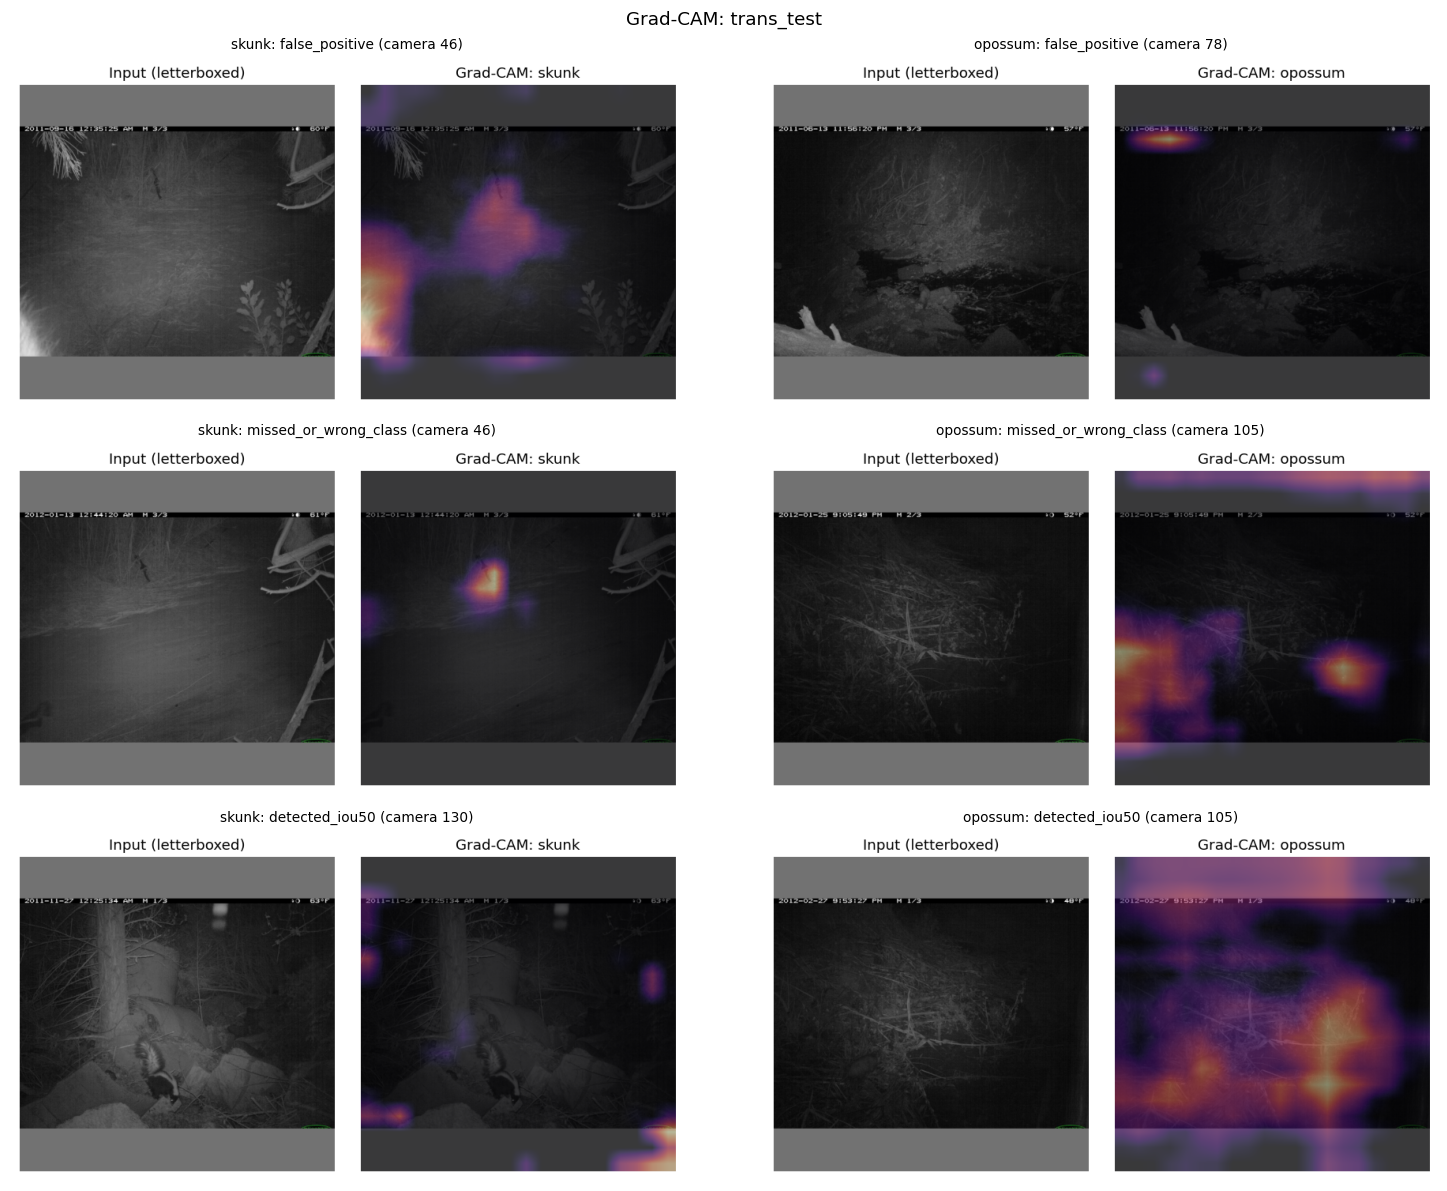

,split,image_id,camera_id,case,period_proxy,training_support,class,proposal,score
0,cis_test,596ef0e9-23d2-11e8-a6a3-ec086b02610b,43,false_positive,day,214,skunk,7248,0.392913
1,cis_test,5968c059-23d2-11e8-a6a3-ec086b02610b,38,false_positive,night,2514,opossum,7481,0.746327
2,cis_test,5975160a-23d2-11e8-a6a3-ec086b02610b,61,missed_or_wrong_class,day,44,deer,8132,0.025478
3,cis_test,5858c152-23d2-11e8-a6a3-ec086b02610b,108,missed_or_wrong_class,night,2514,opossum,7417,0.198545
4,cis_test,59c99e88-23d2-11e8-a6a3-ec086b02610b,61,detected_iou50,day,44,deer,8127,0.005991
5,cis_test,585a6381-23d2-11e8-a6a3-ec086b02610b,88,detected_iou50,night,2514,opossum,7301,0.819745
6,trans_test,596d6622-23d2-11e8-a6a3-ec086b02610b,46,false_positive,day,214,skunk,7561,0.312682
7,trans_test,58c97c14-23d2-11e8-a6a3-ec086b02610b,78,false_positive,night,2514,opossum,4358,0.764838
8,trans_test,59b937e0-23d2-11e8-a6a3-ec086b02610b,46,missed_or_wrong_class,day,214,skunk,7681,0.005450
9,trans_test,585a6409-23d2-11e8-a6a3-ec086b02610b,105,missed_or_wrong_class,night,2514,opossum,7470,0.026377


La brecha observada de mAP50:95 —conocidas menos nuevas— es **16.53 puntos porcentuales**. Los mapas permiten inspeccionar atención sobre animal y entorno, pero no separan causalmente el efecto del fondo, la iluminación, el tamaño ni la composición de especies. La hora es una aproximación, no una etiqueta visual de día/noche. Los intervalos remuestrean secuencias del test con el modelo fijo; no miden variación entre entrenamientos ni regiones futuras.

In [17]:
if not SMOKE:
    display(pd.DataFrame(split_checks))
    camera_table = pd.DataFrame([{"split": split, "cameras": ", ".join(summary["cameras"])}
                                for split, summary in manifest["split_summary"].items()])
    display(camera_table)
    common = [index for index in range(len(names)) if all(scores[split]["per_species"][index]["support"] > 0
                                                       for split in ("cis_test", "trans_test"))]
    common_ap = {split: {key: float(np.mean([scores[split]["per_species"][index][key] for index in common]))
                        for key in ("map50", "map50_95")} for split in ("cis_test", "trans_test")}
    generalization = {"checkpoint_sha256": CHECKPOINT_SHA256,
        "all_species_gap": {key: scores["cis_test"][key] - scores["trans_test"][key] for key in ("map50", "map50_95")},
        "common_species": [names[index] for index in common], "common_species_ap": common_ap,
        "common_species_gap": {key: common_ap["cis_test"][key] - common_ap["trans_test"][key]
                               for key in ("map50", "map50_95")}}
    write_json(OUTPUT / "generalization.json", generalization)
    display(pd.DataFrame([{"comparison": "all supported species", **generalization["all_species_gap"]},
                          {"comparison": "species supported in both tests", **generalization["common_species_gap"]}]))
    uncertainty = {"global": {}, "size": {}, "occlusion": {}}
    for split in ("cis_test", "trans_test"):
        uncertainty["global"][split] = sequence_bootstrap(records[split], predictions[split], names)
    write_json(OUTPUT / "uncertainty.json", uncertainty)
    display(pd.DataFrame([{"split": split, **interval["intervals"]["map50_95"]}
                          for split, interval in uncertainty["global"].items()]))
    cam_cases = []
    for split in ("cis_test", "trans_test"):
        selected = _select_cam_records(manifest, predictions[split], split, 0.25)
        selected_records = {row["image_id"]: row for row in records[split]}
        for index, (original, kind, class_id) in enumerate(selected):
            row = selected_records[original["image_id"]]
            destination = OUTPUT / "cam_cases" / f"{split}_{index}.png"
            details = detection_cam(model, row, None, destination, names, class_id)
            cam_cases.append({"split": split, "image_id": row["image_id"], "camera_id": row["camera_id"],
                              "case": kind, "period_proxy": _capture_period(row),
                              "training_support": manifest["train_class_boxes"][names[class_id]],
                              "figure": str(destination), **details})
        fig, axes = plt.subplots(3, 2, figsize=(14, 11))
        for ax, case in zip(axes.flat, [item for item in cam_cases if item["split"] == split], strict=True):
            with Image.open(case["figure"]) as image:
                ax.imshow(image)
            ax.set_title(f"{case['class']}: {case['case']} (camera {case['camera_id']})", fontsize=9)
            ax.axis("off")
        fig.suptitle(f"Grad-CAM: {split}")
        fig.tight_layout()
        fig.savefig(OUTPUT / f"cam_{split}_grid.png", bbox_inches="tight")
        plt.show()
    write_json(OUTPUT / "cam_cases.json", {"checkpoint_sha256": CHECKPOINT_SHA256, "cases": cam_cases})
    display(pd.DataFrame(cam_cases).drop(columns=["figure", "heatmap_range"]))
    gap = generalization["all_species_gap"]["map50_95"] * 100
    display(Markdown(f"La brecha observada de mAP50:95 —conocidas menos nuevas— es **{gap:.2f} puntos porcentuales**. "
        "Los mapas permiten inspeccionar atención sobre animal y entorno, pero no separan causalmente el efecto del fondo, "
        "la iluminación, el tamaño ni la composición de especies. La hora es una aproximación, no una etiqueta visual de día/noche. "
        "Los intervalos remuestrean secuencias del test con el modelo fijo; no miden variación entre entrenamientos ni regiones futuras."))
else:
    print("Smoke: geographic evaluation and Grad-CAM on held-out tests are omitted.")


## 4. Robustez ante tamaño del objeto y oclusión

Se utiliza el área de cada caja respecto del área de su fotografía: pequeño <1 %,
mediano entre 1 y 5 % —inclusive— y grande >5 %. La evaluación COCO se realiza en una
geometría virtual de 1.000 × 1.000 que conserva IoU y permite esos cortes relativos.
Se mantienen todas las fotografías, incluidas las vacías.

Para cada nivel de oclusión, los objetos no revisados, ambiguos, excluidos o de otro nivel
se marcan como regiones ignoradas `crowd` según COCO. No se eliminan las fotografías
que los contienen. La AP de los 582 casos aceptados es **no ponderada** y condicional
a esa cohorte; no es directamente comparable con la AP global ni un efecto causal
aislado de la oclusión. Los pesos originales se conservan como metadatos de muestreo.

Sequence bootstrap: 20/200; {'area_range': (0, 9999.999999999998)}


Sequence bootstrap: 40/200; {'area_range': (0, 9999.999999999998)}


Sequence bootstrap: 60/200; {'area_range': (0, 9999.999999999998)}


Sequence bootstrap: 80/200; {'area_range': (0, 9999.999999999998)}


Sequence bootstrap: 100/200; {'area_range': (0, 9999.999999999998)}


...

Sequence bootstrap: 160/200; occlusion=high


Sequence bootstrap: 180/200; occlusion=high


Sequence bootstrap: 200/200; occlusion=high


,analysis,split,group,objects,map50,map50_95,classes_with_support,lower,upper,defined_replicates
0,size,cis_test,small_lt_1pct,1149,0.559684,0.277044,12,0.245519,0.345786,200
1,size,cis_test,medium_1_to_5pct,8925,0.762800,0.476229,13,0.461174,0.527649,200
2,size,cis_test,large_gt_5pct,2387,0.760232,0.553298,11,0.535816,0.575712,200
3,size,trans_test,small_lt_1pct,1922,0.340444,0.172209,12,0.148467,0.226986,200
4,size,trans_test,medium_1_to_5pct,12169,0.554097,0.340241,12,0.327685,0.359890,200
5,size,trans_test,large_gt_5pct,3529,0.420183,0.318487,11,0.243081,0.364624,200
6,occlusion,trans_test,low,340,0.189014,0.103260,13,0.086132,0.145305,200
7,occlusion,trans_test,medium,69,0.073448,0.039663,10,0.021711,0.089669,200
8,occlusion,trans_test,high,48,0.037716,0.015091,11,0.009976,0.046481,200


,analysis,split,comparison,gap_pp
0,size,cis_test,large minus small_lt_1pct,27.625309
1,size,cis_test,large minus medium_1_to_5pct,7.706829
2,size,trans_test,large minus small_lt_1pct,14.627863
3,size,trans_test,large minus medium_1_to_5pct,-2.175364
4,occlusion,trans_test,low minus medium,6.359666
5,occlusion,trans_test,low minus high,8.816897


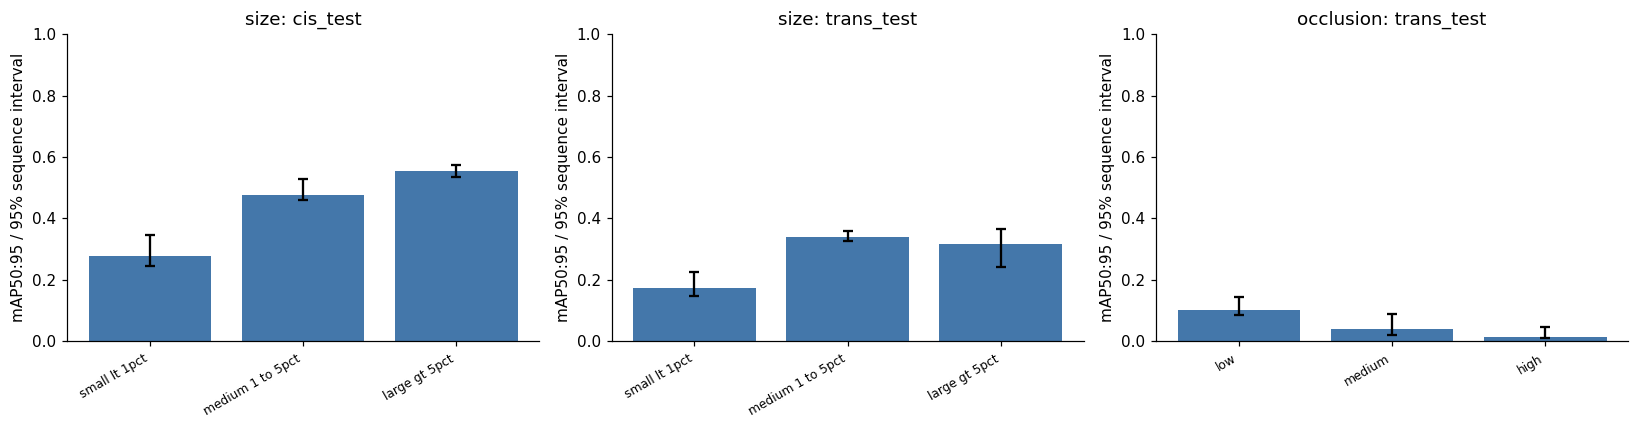

Los grupos difieren en especie, soporte y dificultad. Una diferencia negativa significa que el grupo de referencia no obtuvo mayor AP; no se fuerza una caída esperada. Los intervalos usan 200 remuestreos de secuencias, semilla 42 y checkpoint fijo. No incluyen desacuerdo de anotación, variación entre semillas ni extrapolación a cámaras futuras. No se reutiliza la garantía de muestreo de 600 casos después de las 18 exclusiones por falta de respuesta humana.

In [18]:
if not SMOKE:
    size_ranges = {"small_lt_1pct": (0, float(np.nextafter(10000.0, 0))),
                   "medium_1_to_5pct": (10000, 50000),
                   "large_gt_5pct": (float(np.nextafter(50000.0, np.inf)), 1e10)}
    robustness, robustness_rows = {"size": {}, "occlusion": {}, "checkpoint_sha256": CHECKPOINT_SHA256}, []
    for split in ("cis_test", "trans_test"):
        robustness["size"][split] = {}
        uncertainty["size"][split] = {}
        for group, bounds in size_ranges.items():
            metrics = coco_evaluate(records[split], predictions[split], names, area_range=bounds)
            intervals = sequence_bootstrap(records[split], predictions[split], names, area_range=bounds)
            robustness["size"][split][group] = metrics
            uncertainty["size"][split][group] = intervals
            robustness_rows.append({"analysis": "size", "split": split, "group": group,
                "objects": metrics["eligible_objects"], "map50": metrics["map50"], "map50_95": metrics["map50_95"],
                "classes_with_support": sum(row["support"] > 0 for row in metrics["per_species"]),
                **intervals["intervals"]["map50_95"]})
            write_json(OUTPUT / "robustness_progress.json", robustness_rows)
    occlusions = {row["annotation_id"]: row["level"] for row in review_data["occlusion_reviews"]}
    for level in ("low", "medium", "high"):
        kwargs = {"occlusions": occlusions, "occlusion_group": level}
        metrics = coco_evaluate(records["trans_test"], predictions["trans_test"], names, **kwargs)
        assert metrics["eligible_objects"] == review_data["occlusion_counts"][level] >= 30
        intervals = sequence_bootstrap(records["trans_test"], predictions["trans_test"], names, **kwargs)
        robustness["occlusion"][level] = metrics
        uncertainty["occlusion"][level] = intervals
        robustness_rows.append({"analysis": "occlusion", "split": "trans_test", "group": level,
            "objects": metrics["eligible_objects"], "map50": metrics["map50"], "map50_95": metrics["map50_95"],
            "classes_with_support": sum(row["support"] > 0 for row in metrics["per_species"]),
            **intervals["intervals"]["map50_95"]})
        write_json(OUTPUT / "robustness_progress.json", robustness_rows)
    write_json(OUTPUT / "robustness.json", robustness)
    write_json(OUTPUT / "uncertainty.json", uncertainty)
    write_csv(OUTPUT / "robustness_metrics.csv", robustness_rows)
    robustness_table = pd.DataFrame(robustness_rows)
    display(robustness_table)
    differences = []
    for split, groups in robustness["size"].items():
        reference = groups["large_gt_5pct"]["map50_95"]
        for group in ("small_lt_1pct", "medium_1_to_5pct"):
            current = groups[group]["map50_95"]
            differences.append({"analysis": "size", "split": split, "comparison": f"large minus {group}",
                                "gap_pp": None if reference is None or current is None else 100*(reference-current)})
    for level in ("medium", "high"):
        differences.append({"analysis": "occlusion", "split": "trans_test", "comparison": f"low minus {level}",
            "gap_pp": 100*(robustness["occlusion"]["low"]["map50_95"]-robustness["occlusion"][level]["map50_95"])})
    display(pd.DataFrame(differences))
    write_csv(OUTPUT / "robustness_differences.csv", differences)
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    panels = [("size", "cis_test"), ("size", "trans_test"), ("occlusion", "trans_test")]
    for ax, (analysis, split) in zip(axes, panels, strict=True):
        table = robustness_table[(robustness_table.analysis == analysis) & (robustness_table.split == split)]
        x = np.arange(len(table))
        ax.bar(x, table.map50_95, color="#4477AA")
        # Percentile intervals need not contain the original estimate: draw bounds directly.
        ax.vlines(x, table.lower, table.upper, color="black")
        ax.scatter(x, table.lower, marker="_", color="black")
        ax.scatter(x, table.upper, marker="_", color="black")
        ax.set_xticks(x, table.group.str.replace("_", " "), rotation=30, ha="right", fontsize=8)
        ax.set_ylim(0, 1)
        ax.set_title(f"{analysis}: {split}")
        ax.set_ylabel("mAP50:95 / 95% sequence interval")
    fig.tight_layout()
    fig.savefig(OUTPUT / "robustness_intervals.png", bbox_inches="tight")
    plt.show()
    display(Markdown("Los grupos difieren en especie, soporte y dificultad. Una diferencia negativa significa que "
        "el grupo de referencia no obtuvo mayor AP; no se fuerza una caída esperada. Los intervalos usan 200 "
        "remuestreos de secuencias, semilla 42 y checkpoint fijo. No incluyen desacuerdo de anotación, variación "
        "entre semillas ni extrapolación a cámaras futuras. No se reutiliza la garantía de muestreo de 600 casos "
        "después de las 18 exclusiones por falta de respuesta humana."))
else:
    print("Smoke: scientific robustness and bootstrap are omitted.")


## 5. Monitoreo ecológico: demostración en una cámara nueva

Se elige por ID la primera cámara de `trans_test` que tenga fechas válidas y al menos
una ráfaga completa de dos o más fotografías. La elección no depende del rendimiento
del detector. Se procesan todos sus fotogramas oficiales, incluidos los que no tenían
cajas suficientes para la evaluación de detección. Se muestran la ráfaga y los reportes
por cámara, especie y día. La zona horaria de captura no está declarada: no se transforma.

Working copies monitoring: 1853/1853


monitoring: 8/1853


monitoring: 808/1853


monitoring: 1608/1853


monitoring: 1853/1853


,camera_id,date,photos,photos_with_fauna,empty_photo_rate,distinct_species
0,7,2011-05-07,1,0,1.000000,0
1,7,2011-05-08,9,1,0.888889,2
2,7,2011-05-10,3,1,0.666667,1
3,7,2011-05-20,3,2,0.333333,1
4,7,2011-05-25,2,1,0.500000,1
...,...,...,...,...,...,...
206,7,2012-05-12,15,7,0.533333,1
207,7,2012-05-13,15,15,0.000000,2
208,7,2012-05-14,9,6,0.333333,1
209,7,2012-05-16,3,2,0.333333,1


,camera_id,date,species,detections,photos_with_species
0,7,2011-05-08,bobcat,1,1
1,7,2011-05-08,opossum,1,1
2,7,2011-05-10,coyote,1,1
3,7,2011-05-20,opossum,2,2
4,7,2011-05-25,coyote,2,1
...,...,...,...,...,...
312,7,2012-05-13,opossum,12,12
313,7,2012-05-13,squirrel,6,3
314,7,2012-05-14,opossum,6,6
315,7,2012-05-16,coyote,2,2


,camera_id,sequence_id,image_id,timestamp,frame,detections,species
0,7,6f06c47d-5567-11e8-b8ef-dca9047ef277,597515c6-23d2-11e8-a6a3-ec086b02610b,2011-05-08 11:39:22,1,0,
1,7,6f06c47d-5567-11e8-b8ef-dca9047ef277,5968c329-23d2-11e8-a6a3-ec086b02610b,2011-05-08 11:39:23,2,0,
2,7,6f06c47d-5567-11e8-b8ef-dca9047ef277,59ef8e67-23d2-11e8-a6a3-ec086b02610b,2011-05-08 11:39:24,3,0,


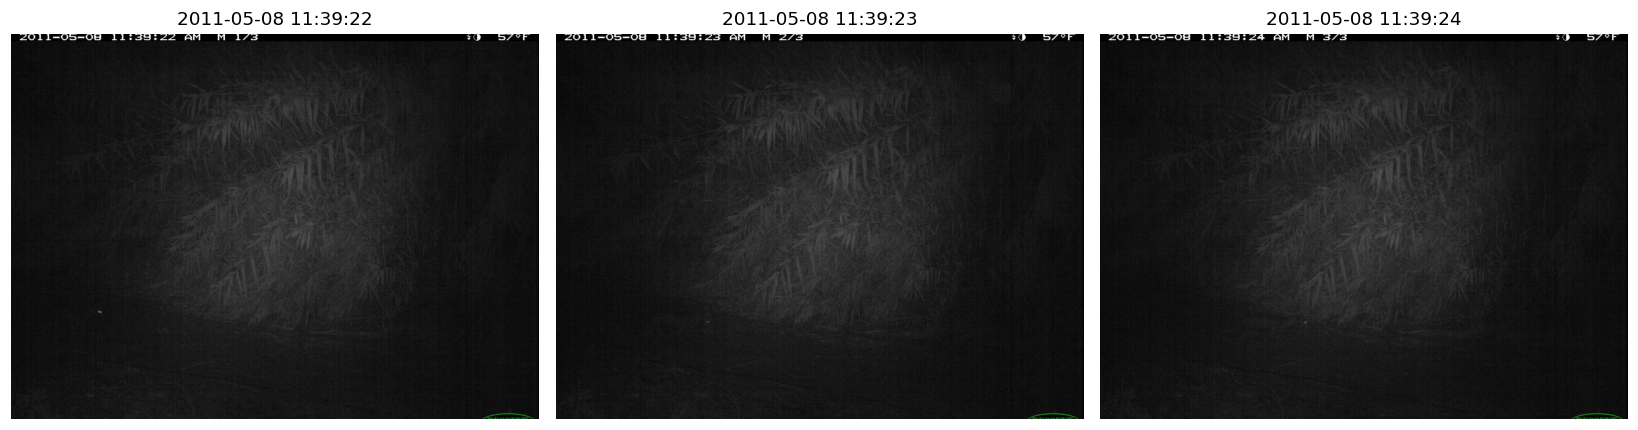

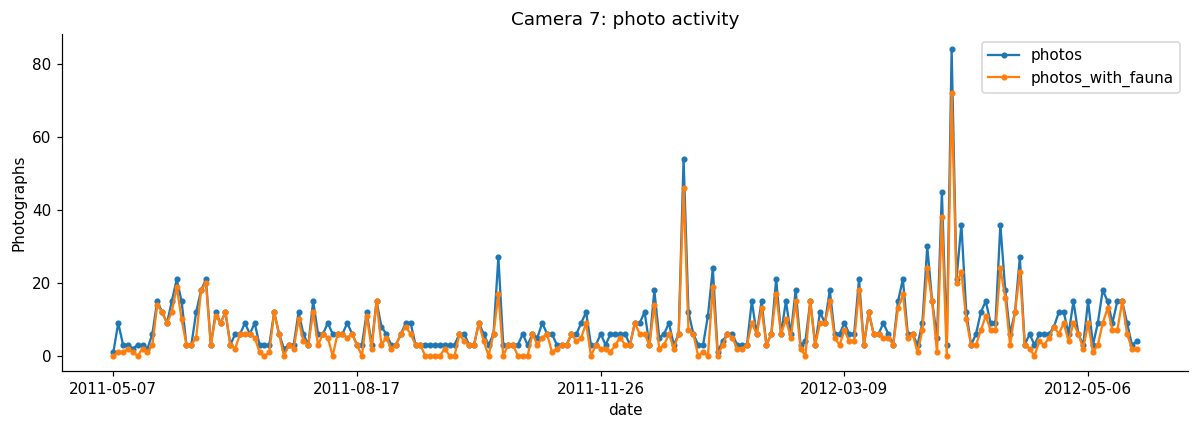

La cámara **7** aporta **1,853 fotografías**. Los conteos son detecciones y fotografías, **no individuos únicos ni estimaciones de población**. Una fotografía con varias cajas de una especie cuenta una sola vez en `photos_with_species`. Las tasas de fotografías vacías se basan en predicciones al umbral 0,25, no en verdad de terreno completa.

In [19]:
def choose_monitoring_camera(frames: list[dict]) -> tuple[list[dict], str]:
    cameras = sorted({row["camera_id"] for row in frames}, key=lambda value: int(value))
    for camera in cameras:
        group = [row for row in frames if row["camera_id"] == camera]
        counts = Counter(row["sequence_id"] for row in group)
        complete = sorted({row["sequence_id"] for row in group
                           if counts[row["sequence_id"]] == row["sequence_frames"] and counts[row["sequence_id"]] >= 2})
        try:
            for row in group:
                datetime.fromisoformat(row["timestamp"].replace("Z", "+00:00"))
        except (ValueError, TypeError):
            continue
        if complete:
            return sorted(group, key=lambda row: (row["timestamp"], row["sequence_id"], row["frame_number"])), complete[0]
    raise ValueError("No held-out camera has valid timestamps and a complete burst.")

if not SMOKE:
    demo_frames, demo_sequence = choose_monitoring_camera(monitoring_frames)
    camera = demo_frames[0]["camera_id"]
    assert camera not in manifest["split_summary"]["train"]["cameras"]
    demo_frames = materialize({"monitoring": demo_frames}, names)["monitoring"]
    demo_predictions = predict_records(model, demo_frames, "monitoring")
    activity = activity_report(demo_frames, demo_predictions, names, confidence=0.25)
    activity.update({"camera_id": camera, "sequence_id": demo_sequence, "checkpoint_sha256": CHECKPOINT_SHA256,
                     "timezone": "unspecified capture timezone; no conversion",
                     "cohort": "all official frames of a predetermined unseen camera"})
    burst = [row for row in demo_frames if row["sequence_id"] == demo_sequence]
    by_image = defaultdict(list)
    for prediction in demo_predictions:
        if prediction["confidence"] >= 0.25:
            by_image[prediction["image_id"]].append(prediction)
    sequence_rows = [{"camera_id": camera, "sequence_id": demo_sequence, "image_id": row["image_id"],
        "timestamp": row["timestamp"], "frame": row["frame_number"], "detections": len(by_image[row["image_id"]]),
        "species": ", ".join(sorted({names[item["class_id"]] for item in by_image[row["image_id"]]}))} for row in burst]
    activity["sequence_frames"] = sequence_rows
    write_json(OUTPUT / "activity.json", activity)
    for key in ("camera_days", "species_days", "sequence_frames"):
        write_csv(OUTPUT / f"activity_{key}.csv", activity[key])
        display(pd.DataFrame(activity[key]))
    fig, axes = plt.subplots(1, len(burst), figsize=(5*len(burst), 4), squeeze=False)
    for ax, row in zip(axes.flat, burst, strict=True):
        with Image.open(row["image"]) as image:
            ax.imshow(image)
            width, height = image.size
        for prediction in by_image[row["image_id"]]:
            x, y, w, h = prediction["bbox"]
            ax.add_patch(patches.Rectangle((x*width, y*height), w*width, h*height,
                                           fill=False, edgecolor="#00E5FF", linewidth=2))
            ax.text(x*width, y*height, f"{names[prediction['class_id']]} {prediction['confidence']:.2f}",
                    backgroundcolor="white", fontsize=8)
        ax.set_title(row["timestamp"])
        ax.axis("off")
    fig.tight_layout()
    fig.savefig(OUTPUT / "monitoring_burst.png", bbox_inches="tight")
    plt.show()
    days = pd.DataFrame(activity["camera_days"])
    fig, ax = plt.subplots(figsize=(11, 4))
    days.plot(x="date", y=["photos", "photos_with_fauna"], ax=ax, marker=".", title=f"Camera {camera}: photo activity")
    ax.set_ylabel("Photographs")
    fig.tight_layout()
    fig.savefig(OUTPUT / "activity_timeline.png", bbox_inches="tight")
    plt.show()
    display(Markdown(f"La cámara **{camera}** aporta **{len(demo_frames):,} fotografías**. "
        "Los conteos son detecciones y fotografías, **no individuos únicos ni estimaciones de población**. "
        "Una fotografía con varias cajas de una especie cuenta una sola vez en `photos_with_species`. "
        "Las tasas de fotografías vacías se basan en predicciones al umbral 0,25, no en verdad de terreno completa."))
else:
    print("Smoke: the held-out ecological demonstration is omitted.")


## 6. Uso responsable de IA en conservación y conclusiones

Un falso negativo puede ocultar la presencia de una especie amenazada y dejarla fuera
de las decisiones de manejo. Su costo depende de la especie, el sitio y la decisión:
la misma tasa de error puede ser tolerable para un resumen exploratorio e inaceptable
para decidir que una especie está ausente. Una detección faltante no demuestra ausencia.
Las especies con pocos ejemplos necesitan revisión específica; una buena mAP global
no garantiza sensibilidad suficiente para ellas.

Un falso positivo consume tiempo del especialista y puede producir registros de presencia
incorrectos. Bajar el umbral puede recuperar animales difíciles, pero también aumentar
la carga de revisión. El umbral operativo de 0,25 de esta demostración debe revisarse con
datos locales y costos definidos por el equipo de conservación. La AP se calcula sobre
muchos umbrales y no sustituye esa decisión operativa. Las imágenes vacías son necesarias
para medir y controlar falsas alarmas.

Un modelo entrenado en cámaras del suroeste de Estados Unidos no queda validado para
la Amazonía o los Andes. Vegetación, iluminación, sensor, colocación de cámara, especies
y frecuencia de aparición pueden cambiar. Antes de desplegarlo se requiere una muestra
local anotada, evaluación por especie y condiciones, y revisión humana de hallazgos
relevantes. Los mapas Grad-CAM ayudan a formular hipótesis sobre el fondo; no certifican
que el detector reconozca rasgos biológicos ni justifican una transferencia sin validación.

El monitoreo debe conservar trazabilidad de datos, versiones, umbral y checkpoint.
Los reportes cuentan eventos de detección y fotografías; varias imágenes pueden contener
el mismo individuo. Tampoco se estima población, ocupación ni esfuerzo de muestreo con
estas tablas. La cohorte de oclusión aceptada conserva exclusiones y notas ausentes;
sus límites deben acompañar cualquier conclusión sobre robustez. El sistema apoya al
especialista, que mantiene la responsabilidad de interpretar la evidencia y decidir.

In [20]:
if not SMOKE:
    assert file_sha256(BEST) == CHECKPOINT_SHA256
    assert all(scores[split]["checkpoint_sha256"] == CHECKPOINT_SHA256 for split in scores)
    assert len(cam_cases) == 12
    assert sum(row["photos"] for row in activity["camera_days"]) == len(demo_frames)
    assert all(interval["replicates"] == 200 for interval in uncertainty["occlusion"].values())
    assert all(file_sha256(DATA_ROOT / relative) == expected for relative, expected in INPUT_HASHES.items())
    # Recheck every audited source byte after all loader/training/inference operations.
    source_paths = {row["source"]: row["source_sha256"] for rows in manifest["records"].values() for row in rows}
    source_paths.update({row["source"]: row["source_sha256"] for row in monitoring_frames})
    for source, expected in source_paths.items():
        assert file_sha256(Path(source)) == expected, f"Source changed: {source}"
    evidence = [
        {"deliverable": "1. Adjusted YOLO", "evidence": f"{len(training)} epochs; new best.pt; 90 human reviews retained", "status": "complete"},
        {"deliverable": "2. Quantitative evaluation", "evidence": "New cis/trans predictions; AP50 and AP50:95; per-species support", "status": "complete"},
        {"deliverable": "3. Camera generalization", "evidence": f"Disjoint sequences; unseen cameras; gap and {len(cam_cases)} Grad-CAM cases", "status": "complete"},
        {"deliverable": "4. Robustness", "evidence": "3 sizes per test; 3 accepted occlusion levels; 200 sequence replicates per group", "status": "complete"},
        {"deliverable": "5. Ecological monitoring", "evidence": f"Unseen camera {camera}; {len(demo_frames)} frames; complete burst; daily species tables", "status": "complete"},
        {"deliverable": "6. Responsible use", "evidence": "Written discussion of FN, FP, regional transfer and limitations", "status": "complete"}]
    COMPLETION = {"status": "complete", "scientific_run": True, "output": str(OUTPUT),
        "checkpoint_sha256": CHECKPOINT_SHA256, "pretrained_sha256": PRETRAINED_SHA256,
        "manifest_identity": manifest["identity"], "versions": VERSIONS, "unit_checks": UNIT_CHECKS,
        "input_originals_unchanged": True, "deliverables": evidence,
        "completed_at_utc": datetime.now(timezone.utc).isoformat()}
    write_json(OUTPUT / "completion.json", COMPLETION)
    display(pd.DataFrame(evidence))
    print("Complete scientific execution. New artifacts:", OUTPUT)
    print("Checkpoint SHA-256:", CHECKPOINT_SHA256)
    if TRAINING_CACHE is not None:
        TRAINING_CACHE.cleanup()
else:
    write_json(OUTPUT / "completion.json", {"status": "smoke_passed", "scientific_run": False,
        "unit_checks": UNIT_CHECKS, "test_partitions_used": [], "training": TRAINING_RECEIPT})
    print("Isolated smoke passed. No scientific performance claim is made from this run.")


,deliverable,evidence,status
0,1. Adjusted YOLO,48 epochs; new best.pt; 90 human reviews retained,complete
1,2. Quantitative evaluation,New cis/trans predictions; AP50 and AP50:95; p...,complete
2,3. Camera generalization,Disjoint sequences; unseen cameras; gap and 12...,complete
3,4. Robustness,3 sizes per test; 3 accepted occlusion levels;...,complete
4,5. Ecological monitoring,Unseen camera 7; 1853 frames; complete burst; ...,complete
5,6. Responsible use,"Written discussion of FN, FP, regional transfe...",complete


Complete scientific execution. New artifacts: E:\Kaggle\exam-output-wildlife-notebook\full-20261025T222726_615921Z
Checkpoint SHA-256: 30c66beafdae0619acf91c4f9a4c50c8c4ecd244724c24328c0f254369b6031e
